## Imports

In [5]:
%pip install -q scikit-learn numpy pandas matplotlib ipython
import time
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

from sklearn.datasets import load_diabetes, load_breast_cancer, load_digits, load_iris
from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold
from sklearn.metrics import (
    mean_squared_error, r2_score, accuracy_score, confusion_matrix as sklearn_confusion_matrix,
    precision_recall_fscore_support, roc_auc_score
)
from sklearn.linear_model import LinearRegression, Ridge, SGDRegressor, LogisticRegression
from sklearn.svm import SVC, LinearSVC

warnings.filterwarnings("ignore", category=FutureWarning)
np.set_printoptions(precision=5, suppress=True)

RANDOM_GENERATOR = np.random.default_rng(42)
RANDOM_STATE = 42



[notice] A new release of pip available: 22.3 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


Note: you may need to restart the kernel to use updated packages.


## Part A
task 1-4



In [6]:

def make_train_validation_test_split(features, targets, is_classification):
    """Return train, validation, and test splits using the assignment protocol."""
    if is_classification:
        stratify_for_test = targets
    else:
        stratify_for_test = None

    training_features, test_features, training_targets, test_targets = train_test_split(
        features,
        targets,
        test_size=0.20,
        random_state=RANDOM_STATE,
        stratify=stratify_for_test
    )

    if is_classification:
        stratify_for_validation = training_targets
    else:
        stratify_for_validation = None

    training_features, validation_features, training_targets, validation_targets = train_test_split(
        training_features,
        training_targets,
        test_size=0.25,
        random_state=RANDOM_STATE,
        stratify=stratify_for_validation
    )

    return (
        training_features, validation_features, test_features,
        training_targets, validation_targets, test_targets
    )


def print_split_information(dataset_name, split_data, is_classification):
    """Print each split size and, for classification, its class counts."""
    training_features, validation_features, test_features = split_data[0:3]
    training_targets, validation_targets, test_targets = split_data[3:6]

    print(f"\n{dataset_name}")
    for split_name, split_features, split_targets in [
        ("Train", training_features, training_targets),
        ("Validation", validation_features, validation_targets),
        ("Test", test_features, test_targets)
    ]:
        print(f"{split_name:10s}: {len(split_features)} rows")
        if is_classification:
            class_values, class_counts = np.unique(split_targets, return_counts=True)
            print("             class counts:", dict(zip(class_values.tolist(), class_counts.tolist())))


# Diabetes: scaled=False is required so that Task 7 can compare raw and standardized features.
diabetes_data = load_diabetes(scaled=False)
diabetes_features = diabetes_data.data
diabetes_targets = diabetes_data.target

diabetes_splits = make_train_validation_test_split(
    diabetes_features, diabetes_targets, is_classification=False
)

# Breast cancer: make malignant = 1 positive and benign = 0.
breast_cancer_data = load_breast_cancer()
breast_cancer_features = breast_cancer_data.data
breast_cancer_targets = 1 - breast_cancer_data.target
breast_cancer_splits = make_train_validation_test_split(
    breast_cancer_features, breast_cancer_targets, is_classification=True
)

# Digits: labels are already integers 0 through 9.
digits_data = load_digits()
digits_features = digits_data.data / 16.0
digits_targets = digits_data.target
digits_splits = make_train_validation_test_split(
    digits_features, digits_targets, is_classification=True
)

# Iris: labels are already integers 0, 1, and 2.
iris_data = load_iris()
iris_features = iris_data.data
iris_targets = iris_data.target
iris_splits = make_train_validation_test_split(
    iris_features, iris_targets, is_classification=True
)

print_split_information("Diabetes", diabetes_splits, False)
print_split_information("Breast cancer", breast_cancer_splits, True)
print_split_information("Digits", digits_splits, True)
print_split_information("Iris", iris_splits, True)

expected_split_sizes = {
    "Diabetes": (264, 89, 89),
    "Breast cancer": (341, 114, 114),
    "Digits": (1077, 360, 360),
    "Iris": (90, 30, 30)
}
actual_split_sizes = {
    "Diabetes": tuple(len(part) for part in diabetes_splits[:3]),
    "Breast cancer": tuple(len(part) for part in breast_cancer_splits[:3]),
    "Digits": tuple(len(part) for part in digits_splits[:3]),
    "Iris": tuple(len(part) for part in iris_splits[:3])
}
assert actual_split_sizes == expected_split_sizes
print("\n All split sizes match the assignment table.")


Diabetes
Train     : 264 rows
Validation: 89 rows
Test      : 89 rows

Breast cancer
Train     : 341 rows
             class counts: {0: 214, 1: 127}
Validation: 114 rows
             class counts: {0: 71, 1: 43}
Test      : 114 rows
             class counts: {0: 72, 1: 42}

Digits
Train     : 1077 rows
             class counts: {0: 106, 1: 109, 2: 107, 3: 109, 4: 109, 5: 109, 6: 109, 7: 107, 8: 104, 9: 108}
Validation: 360 rows
             class counts: {0: 36, 1: 37, 2: 35, 3: 37, 4: 36, 5: 36, 6: 36, 7: 36, 8: 35, 9: 36}
Test      : 360 rows
             class counts: {0: 36, 1: 36, 2: 35, 3: 37, 4: 36, 5: 37, 6: 36, 7: 36, 8: 35, 9: 36}

Iris
Train     : 90 rows
             class counts: {0: 30, 1: 30, 2: 30}
Validation: 30 rows
             class counts: {0: 10, 1: 10, 2: 10}
Test      : 30 rows
             class counts: {0: 10, 1: 10, 2: 10}

 All split sizes match the assignment table.


In [7]:
#Task 2
class Standardizer:
    """Standardize columns using means and standard deviations from training data."""

    def fit(self, training_features):
        self.feature_means = np.mean(training_features, axis=0)
        self.feature_standard_deviations = np.std(training_features, axis=0)
        self.feature_standard_deviations[self.feature_standard_deviations == 0] = 1.0
        return self

    def transform(self, features):
        return (features - self.feature_means) / self.feature_standard_deviations

    def fit_transform(self, training_features):
        self.fit(training_features)
        return self.transform(training_features)


def add_bias_column(features):
    """Add a first column of ones so the intercept is part of the weight vector."""
    number_of_rows = features.shape[0]
    return np.column_stack((np.ones(number_of_rows), features))


def standardize_split(split_data):
    """Fit on training rows and apply the same transformation to all three splits."""
    training_features, validation_features, test_features = split_data[:3]
    standardizer = Standardizer()
    standardized_training_features = standardizer.fit_transform(training_features)
    standardized_validation_features = standardizer.transform(validation_features)
    standardized_test_features = standardizer.transform(test_features)
    return (
        standardized_training_features,
        standardized_validation_features,
        standardized_test_features,
        standardizer
    )

(
    diabetes_train, diabetes_validation, diabetes_test, diabetes_standardizer
) = standardize_split(diabetes_splits)
(
    cancer_train, cancer_validation, cancer_test, cancer_standardizer
) = standardize_split(breast_cancer_splits)

# Digits are divided by 16 as required and are not standardized.
digits_train, digits_validation, digits_test = digits_splits[:3]

(
    iris_train, iris_validation, iris_test, iris_standardizer
) = standardize_split(iris_splits)

print("Largest absolute standardized Diabetes training mean:",
      np.max(np.abs(np.mean(diabetes_train, axis=0))))
print("Smallest / largest Diabetes training standard deviation:",
      np.min(np.std(diabetes_train, axis=0)), np.max(np.std(diabetes_train, axis=0)))
assert np.max(np.abs(np.mean(diabetes_train, axis=0))) < 1e-9
assert np.max(np.abs(np.std(diabetes_train, axis=0) - 1.0)) < 1e-9

print("Validation feature means (not expected to be zero):", np.mean(diabetes_validation, axis=0))
print("Test feature means (not expected to be zero):", np.mean(diabetes_test, axis=0))


Largest absolute standardized Diabetes training mean: 2.2372676102294822e-15
Smallest / largest Diabetes training standard deviation: 0.9999999999999979 1.0000000000000004
Validation feature means (not expected to be zero): [ 0.02306 -0.14585  0.04301  0.19333  0.14308  0.04007  0.21744 -0.02896
  0.01042 -0.22111]
Test feature means (not expected to be zero): [-0.14885 -0.05594 -0.17199 -0.07271  0.093    0.09193  0.16346 -0.04716
 -0.12949 -0.25462]


Fit preprocessing statistics on training rows only so validation and test data do not influence the model
Using all rows leaks information about the held out data and makes the reported test performance misleading

In [8]:
#Task3

def mean_squared_error_from_scratch(true_values, predicted_values):
    differences = true_values - predicted_values
    return np.mean(differences ** 2)


def root_mean_squared_error(true_values, predicted_values):
    return np.sqrt(mean_squared_error_from_scratch(true_values, predicted_values))


def coefficient_of_determination(true_values, predicted_values):
    total_sum_of_squares = np.sum((true_values - np.mean(true_values)) ** 2)
    residual_sum_of_squares = np.sum((true_values - predicted_values) ** 2)
    return 1.0 - residual_sum_of_squares / total_sum_of_squares


def classification_accuracy(true_labels, predicted_labels):
    return np.mean(true_labels == predicted_labels)


def confusion_matrix_from_scratch(true_labels, predicted_labels, number_of_classes):
    """Rows are true classes and columns are predicted classes; uses vectorized counting."""
    result_matrix = np.zeros((number_of_classes, number_of_classes), dtype=int)
    np.add.at(result_matrix, (true_labels.astype(int), predicted_labels.astype(int)), 1)
    return result_matrix


def per_class_precision_recall_f1(confusion_matrix):
    true_positive_counts = np.diag(confusion_matrix).astype(float)
    predicted_positive_counts = np.sum(confusion_matrix, axis=0).astype(float)
    actual_positive_counts = np.sum(confusion_matrix, axis=1).astype(float)

    # Precision is defined as 0 for a class that is never predicted.
    class_precision = np.divide(
        true_positive_counts,
        predicted_positive_counts,
        out=np.zeros_like(true_positive_counts),
        where=predicted_positive_counts != 0
    )
    class_recall = np.divide(
        true_positive_counts,
        actual_positive_counts,
        out=np.zeros_like(true_positive_counts),
        where=actual_positive_counts != 0
    )
    class_f1 = np.divide(
        2 * class_precision * class_recall,
        class_precision + class_recall,
        out=np.zeros_like(class_precision),
        where=(class_precision + class_recall) != 0
    )

    return {
        "precision": class_precision,
        "recall": class_recall,
        "f1": class_f1,
        "macro_precision": np.mean(class_precision),
        "macro_recall": np.mean(class_recall),
        "macro_f1": np.mean(class_f1)
    }


# Compare the implemented metrics with scikit-learn on random labels.
metric_random_generator = np.random.default_rng(42)
random_true_classes = metric_random_generator.integers(0, 4, size=500)
random_predicted_classes = metric_random_generator.integers(0, 4, size=500)
random_regression_targets = metric_random_generator.normal(size=500)
random_regression_predictions = metric_random_generator.normal(size=500)

assert np.isclose(
    classification_accuracy(random_true_classes, random_predicted_classes),
    accuracy_score(random_true_classes, random_predicted_classes), atol=1e-12
)
assert np.array_equal(
    confusion_matrix_from_scratch(random_true_classes, random_predicted_classes, 4),
    sklearn_confusion_matrix(random_true_classes, random_predicted_classes, labels=[0, 1, 2, 3])
)
manual_class_metrics = per_class_precision_recall_f1(
    confusion_matrix_from_scratch(random_true_classes, random_predicted_classes, 4)
)
sklearn_precision, sklearn_recall, sklearn_f1, _ = precision_recall_fscore_support(
    random_true_classes, random_predicted_classes, labels=[0, 1, 2, 3], zero_division=0
)
assert np.allclose(manual_class_metrics["precision"], sklearn_precision, atol=1e-12)
assert np.allclose(manual_class_metrics["recall"], sklearn_recall, atol=1e-12)
assert np.allclose(manual_class_metrics["f1"], sklearn_f1, atol=1e-12)
assert np.isclose(
    mean_squared_error_from_scratch(random_regression_targets, random_regression_predictions),
    mean_squared_error(random_regression_targets, random_regression_predictions), atol=1e-12
)
assert np.isclose(
    root_mean_squared_error(random_regression_targets, random_regression_predictions),
    np.sqrt(mean_squared_error(random_regression_targets, random_regression_predictions)), atol=1e-12
)
assert np.isclose(
    coefficient_of_determination(random_regression_targets, random_regression_predictions),
    r2_score(random_regression_targets, random_regression_predictions), atol=1e-12
)
print("all requested metric checks passed")

all requested metric checks passed


In [9]:
#task4

def gradient_check(loss_function, gradient_function, weights, epsilon=1e-5,
                   number_of_entries=None, random_generator=None):
    """Compare an analytic gradient with central finite differences."""
    if random_generator is None:
        random_generator = np.random.default_rng(42)

    weights = np.asarray(weights, dtype=float)
    analytic_gradient = np.asarray(gradient_function(weights), dtype=float)
    numerical_gradient = np.zeros_like(weights, dtype=float)

    flat_weights = weights.reshape(-1)
    flat_numerical_gradient = numerical_gradient.reshape(-1)

    if number_of_entries is None or number_of_entries >= flat_weights.size:
        checked_flat_indices = np.arange(flat_weights.size)
    else:
        checked_flat_indices = random_generator.choice(
            flat_weights.size, size=number_of_entries, replace=False
        )

    for flat_index in checked_flat_indices:
        positive_weights = flat_weights.copy()
        negative_weights = flat_weights.copy()
        positive_weights[flat_index] += epsilon
        negative_weights[flat_index] -= epsilon

        positive_loss = loss_function(positive_weights.reshape(weights.shape))
        negative_loss = loss_function(negative_weights.reshape(weights.shape))
        flat_numerical_gradient[flat_index] = (positive_loss - negative_loss) / (2 * epsilon)

    flat_analytic_gradient = analytic_gradient.reshape(-1)
    selected_analytic_gradient = flat_analytic_gradient[checked_flat_indices]
    selected_numerical_gradient = flat_numerical_gradient[checked_flat_indices]

    numerator = np.linalg.norm(selected_analytic_gradient - selected_numerical_gradient)
    denominator = max(
        np.linalg.norm(selected_analytic_gradient),
        np.linalg.norm(selected_numerical_gradient),
        1e-12
    )
    return numerator / denominator

print("Gradient checker is ready")

Gradient checker is ready


## Part B  Linear regression

In [10]:

def linear_regression_loss(weights, features_with_bias, true_values):
    number_of_samples = len(true_values)
    prediction_errors = features_with_bias @ weights - true_values
    return np.sum(prediction_errors ** 2) / (2 * number_of_samples)


def linear_regression_gradient(weights, features_with_bias, true_values):
    number_of_samples = len(true_values)
    prediction_errors = features_with_bias @ weights - true_values
    return features_with_bias.T @ prediction_errors / number_of_samples


def normal_equation(features, true_values):
    features_with_bias = add_bias_column(features)
    left_side = features_with_bias.T @ features_with_bias
    right_side = features_with_bias.T @ true_values
    # Use solve(), as required; do not calculate an explicit matrix inverse.
    return np.linalg.solve(left_side, right_side)


def ridge_closed_form(features, true_values, regularization_strength):
    features_with_bias = add_bias_column(features)
    number_of_samples = len(true_values)
    number_of_parameters = features_with_bias.shape[1]
    regularization_matrix = np.eye(number_of_parameters)
    regularization_matrix[0, 0] = 0.0  # Do not penalize the bias.

    left_side = features_with_bias.T @ features_with_bias / number_of_samples
    left_side += regularization_strength * regularization_matrix
    right_side = features_with_bias.T @ true_values / number_of_samples
    return np.linalg.solve(left_side, right_side)


def train_batch_linear_regression(features, true_values, learning_rate, number_of_epochs,
                                  regularization_strength=0.0, initial_weights=None):
    features_with_bias = add_bias_column(features)
    number_of_samples, number_of_parameters = features_with_bias.shape
    if initial_weights is None:
        weights = np.zeros(number_of_parameters)
    else:
        weights = initial_weights.astype(float).copy()

    regularization_mask = np.ones(number_of_parameters)
    regularization_mask[0] = 0.0
    loss_history = []
    weight_history = []

    for epoch_number in range(number_of_epochs):
        prediction_errors = features_with_bias @ weights - true_values
        gradient = features_with_bias.T @ prediction_errors / number_of_samples
        gradient += regularization_strength * regularization_mask * weights
        weights -= learning_rate * gradient

        data_loss = linear_regression_loss(weights, features_with_bias, true_values)
        loss_history.append(data_loss)
        weight_history.append(weights.copy())
        if not np.all(np.isfinite(weights)) or not np.isfinite(data_loss):
            break

    return weights, np.asarray(loss_history), np.asarray(weight_history)


def linear_relative_distance(current_weights, optimal_weights):
    return np.linalg.norm(current_weights - optimal_weights) / max(np.linalg.norm(optimal_weights), 1e-12)


def evaluate_regression_weights(weights, training_features, validation_features, test_features,
                                training_targets, validation_targets, test_targets):
    training_predictions = add_bias_column(training_features) @ weights
    validation_predictions = add_bias_column(validation_features) @ weights
    test_predictions = add_bias_column(test_features) @ weights
    return {
        "train_rmse": root_mean_squared_error(training_targets, training_predictions),
        "validation_rmse": root_mean_squared_error(validation_targets, validation_predictions),
        "test_rmse": root_mean_squared_error(test_targets, test_predictions),
        "test_r2": coefficient_of_determination(test_targets, test_predictions)
    }


In [11]:
#task5

diabetes_training_targets = diabetes_splits[3]
diabetes_validation_targets = diabetes_splits[4]
diabetes_test_targets = diabetes_splits[5]

closed_form_weights = normal_equation(diabetes_train, diabetes_training_targets)
closed_form_metrics = evaluate_regression_weights(
    closed_form_weights,
    diabetes_train, diabetes_validation, diabetes_test,
    diabetes_training_targets, diabetes_validation_targets, diabetes_test_targets
)
condition_number_standardized = np.linalg.cond(add_bias_column(diabetes_train).T @ add_bias_column(diabetes_train))

linear_regression_library = LinearRegression()
linear_regression_library.fit(diabetes_train, diabetes_training_targets)
library_closed_form_weights = np.concatenate((
    [linear_regression_library.intercept_], linear_regression_library.coef_
))
weight_difference = np.max(np.abs(closed_form_weights - library_closed_form_weights))

feature_weight_table = pd.DataFrame({
    "Feature": ["bias"] + list(diabetes_data.feature_names),
    "Weight": closed_form_weights,
    "Train RMSE": closed_form_metrics["train_rmse"],
    "Validation RMSE": closed_form_metrics["validation_rmse"],
    "Test RMSE": closed_form_metrics["test_rmse"],
    "Test R2": closed_form_metrics["test_r2"],
    "Condition number": condition_number_standardized
})
print(feature_weight_table.to_string(index=False))
print("\nRegression metrics:", closed_form_metrics)
print("Condition number:", condition_number_standardized)
print("Maximum difference from LinearRegression weights:", weight_difference)
assert weight_difference < 1e-6


Feature     Weight  Train RMSE  Validation RMSE  Test RMSE  Test R2  Condition number
   bias 149.810606   54.610364        51.193714  54.156413 0.446426        505.706123
    age   1.131837   54.610364        51.193714  54.156413 0.446426        505.706123
    sex -11.359311   54.610364        51.193714  54.156413 0.446426        505.706123
    bmi  25.076618   54.610364        51.193714  54.156413 0.446426        505.706123
     bp  15.167338   54.610364        51.193714  54.156413 0.446426        505.706123
     s1 -51.101359   54.610364        51.193714  54.156413 0.446426        505.706123
     s2  27.480823   54.610364        51.193714  54.156413 0.446426        505.706123
     s3  10.840294   54.610364        51.193714  54.156413 0.446426        505.706123
     s4  15.032148   54.610364        51.193714  54.156413 0.446426        505.706123
     s5  37.271588   54.610364        51.193714  54.156413 0.446426        505.706123
     s6   3.817112   54.610364        51.193714  54.15

While bmi and s2 have large positive weights (indicating higher values increase predicted disease progression), s1 has a large negative weight of comparable magnitude, even though total cholesterol (s1) and LDL (s2) are both biologically associated with higher diabetes risk. Because s1 and s2 are strongly positively correlated (multicollinear), the linear model assigns them large opposing weights that partially cancel each other out to fit subtle noise in the training set rather than reflecting their independent effects. Consequently, interpreting individual weights in isolation is risky because correlated features cause high variance in coefficient estimates—small changes in the training data can dramatically flip their signs or magnitudes without affecting the model's overall predictions.

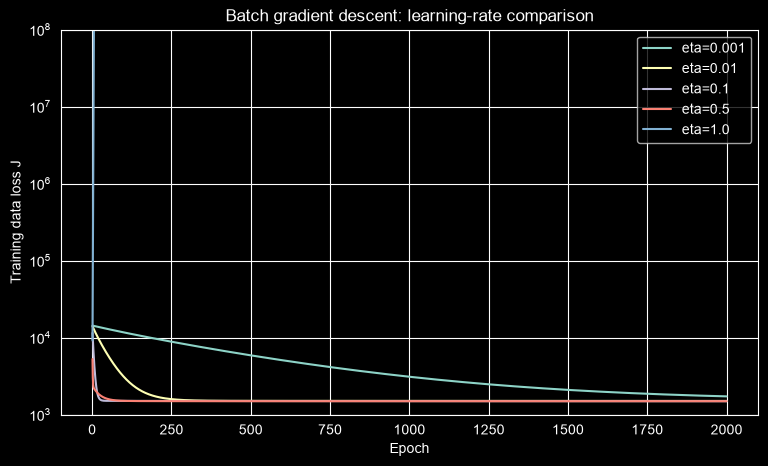

,learning_rate,final_loss,final_relative_distance,first_epoch_below_1e-3,diverged
0,0.001,1723.402889,4.051131e-01,not reached,False
1,0.010,1503.686676,3.345214e-01,not reached,False
2,0.100,1491.892636,8.179229e-02,not reached,False
3,0.500,1491.145907,1.546262e-04,1524,False
4,1.000,inf,4.002419e+150,not reached,True


Largest eigenvalue: 3.9547550320503744
Theoretical learning-rate threshold 2 / largest_eigenvalue: 0.5057203249737277


,run,learning_rate,final_loss,diverged
0,below_threshold,0.480434,1.492930e+03,False
1,above_threshold,0.531006,5.971177e+27,True


In [12]:
# task6
learning_rates_to_test = [0.001, 0.01, 0.1, 0.5, 1.0]
number_of_gradient_descent_epochs = 2000

linear_gradient_descent_results = {}
linear_gradient_descent_rows = []

with np.errstate(over="ignore", invalid="ignore"):
    for learning_rate in learning_rates_to_test:
        final_weights, loss_history, weight_history = train_batch_linear_regression(
            diabetes_train, diabetes_training_targets,
            learning_rate, number_of_gradient_descent_epochs
        )
        distance_history = np.array([
            linear_relative_distance(epoch_weights, closed_form_weights)
            for epoch_weights in weight_history
        ])
        reached_indices = np.where(distance_history < 1e-3)[0]
        first_epoch_reached = int(reached_indices[0] + 1) if len(reached_indices) else "not reached"

        linear_gradient_descent_results[learning_rate] = {
            "weights": final_weights,
            "loss_history": loss_history,
            "distance_history": distance_history
        }
        linear_gradient_descent_rows.append({
            "learning_rate": learning_rate,
            "final_loss": loss_history[-1] if len(loss_history) else np.nan,
            "final_relative_distance": distance_history[-1] if len(distance_history) else np.nan,
            "first_epoch_below_1e-3": first_epoch_reached,
            "diverged": (
                not np.all(np.isfinite(final_weights))
                or not np.isfinite(loss_history[-1])
                or loss_history[-1] > 1e20
            )
        })

plt.figure(figsize=(9, 5))
for learning_rate, result in linear_gradient_descent_results.items():
    losses = np.asarray(result["loss_history"], dtype=float)
    safe_losses = np.where(
        np.isfinite(losses) & (losses < 1e10),
        np.maximum(losses, 1e-15),
        np.nan
    )
    plt.plot(np.arange(1, len(safe_losses) + 1), safe_losses, label=f"eta={learning_rate}")

plt.yscale("log")
plt.ylim(1e3, 1e8)
plt.xlabel("Epoch")
plt.ylabel("Training data loss J")
plt.title("Batch gradient descent: learning-rate comparison")
plt.legend()
plt.grid(True)
plt.show()

linear_gradient_descent_table = pd.DataFrame(linear_gradient_descent_rows)
display(linear_gradient_descent_table)

features_with_bias = add_bias_column(diabetes_train)
hessian_matrix = features_with_bias.T @ features_with_bias / len(diabetes_training_targets)
largest_eigenvalue = np.max(np.linalg.eigvalsh(hessian_matrix))
learning_rate_limit = 2.0 / largest_eigenvalue
print("Largest eigenvalue:", largest_eigenvalue)
print("Theoretical learning-rate threshold 2 / largest_eigenvalue:", learning_rate_limit)

threshold_learning_rates = {
    "below_threshold": 0.95 * learning_rate_limit,
    "above_threshold": 1.05 * learning_rate_limit
}
threshold_rows = []
with np.errstate(over="ignore", invalid="ignore"):
    for schedule_name, learning_rate in threshold_learning_rates.items():
        threshold_weights, threshold_losses, _ = train_batch_linear_regression(
            diabetes_train, diabetes_training_targets, learning_rate, 300
        )
        threshold_rows.append({
            "run": schedule_name,
            "learning_rate": learning_rate,
            "final_loss": threshold_losses[-1] if len(threshold_losses) else np.nan,
            "diverged": (
                not np.all(np.isfinite(threshold_weights))
                or not np.isfinite(threshold_losses[-1])
                or threshold_losses[-1] > 1e20
            )
        })
display(pd.DataFrame(threshold_rows))



Derivation note:
along an eigenvector with eigenvalue q, the error is multiplied by (1 - eta*q)
Convergence requires |1 - eta*q| < 1 for every eigenvalue; the strict upper bound is eta < 2 / lambda_max.

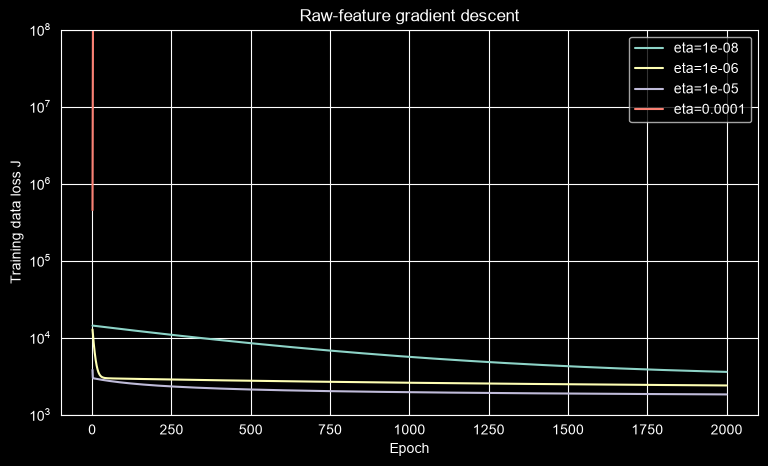

,learning_rate,final_loss,relative_distance,diverged
0,1.000000e-08,3583.532102,9.999986e-01,False
1,1.000000e-06,2388.752582,9.999676e-01,False
2,1.000000e-05,1827.534910,9.998464e-01,False
3,1.000000e-04,inf,1.366696e+148,True


Standardized condition number: 505.7061226961105
Raw-feature condition number: 55778473.21852342
Standardized 2/lambda_max: 0.5057203249737277
Raw-feature 2/lambda_max: 2.7427928748390996e-05


In [13]:
# task7
raw_diabetes_train = diabetes_splits[0]
raw_diabetes_validation = diabetes_splits[1]
raw_diabetes_test = diabetes_splits[2]
raw_learning_rates = [1e-8, 1e-6, 1e-5, 1e-4]
raw_optimal_weights = normal_equation(raw_diabetes_train, diabetes_training_targets)
raw_features_with_bias = add_bias_column(raw_diabetes_train)
raw_hessian = raw_features_with_bias.T @ raw_features_with_bias / len(diabetes_training_targets)
raw_largest_eigenvalue = np.max(np.linalg.eigvalsh(raw_hessian))
raw_learning_rate_limit = 2.0 / raw_largest_eigenvalue
raw_condition_number = np.linalg.cond(raw_features_with_bias.T @ raw_features_with_bias)

raw_gradient_descent_rows = []
raw_gradient_descent_results = {}

# Changed: wrapped the training loop in np.errstate to suppress expected float64 overflow
# warnings when eta=1e-4 (which exceeds 2/lambda_max) diverges to infinity.
with np.errstate(over="ignore", invalid="ignore"):
    for learning_rate in raw_learning_rates:
        raw_weights, raw_losses, raw_weight_history = train_batch_linear_regression(
            raw_diabetes_train, diabetes_training_targets, learning_rate, 2000
        )
        raw_gradient_descent_results[learning_rate] = raw_losses
        raw_gradient_descent_rows.append({
            "learning_rate": learning_rate,
            "final_loss": raw_losses[-1] if len(raw_losses) else np.nan,
            "relative_distance": linear_relative_distance(raw_weights, raw_optimal_weights),
            "diverged": (
                not np.all(np.isfinite(raw_weights))
                or not np.isfinite(raw_losses[-1])
                or raw_losses[-1] > 1e20
            )
        })

plt.figure(figsize=(9, 5))
for learning_rate, loss_history in raw_gradient_descent_results.items():
    # Changed: replaced raw np.maximum(loss_history, 1e-15) with np.where masking inf/nan
    # and values > 1e10 as np.nan. Passing huge exploded floats (~1e300) or inf from eta=1e-4
    # to a log-scale plot overflows Matplotlib's axis tick locator and leaves the plot blank.
    losses = np.asarray(loss_history, dtype=float)
    safe_losses = np.where(
        np.isfinite(losses) & (losses < 1e10),
        np.maximum(losses, 1e-15),
        np.nan
    )
    plt.plot(np.arange(1, len(safe_losses) + 1), safe_losses,
             label=f"eta={learning_rate:g}")

plt.yscale("log")
# Changed: added fixed y-limits so the converging curves remain clearly visible and
# aren't compressed or broken by the diverging eta=1e-4 trajectory shooting off the top.
plt.ylim(1e3, 1e8)
plt.xlabel("Epoch")
plt.ylabel("Training data loss J")
plt.title("Raw-feature gradient descent")
plt.legend()
plt.grid(True)
plt.show()

display(pd.DataFrame(raw_gradient_descent_rows))
print("Standardized condition number:", condition_number_standardized)
print("Raw-feature condition number:", raw_condition_number)
print("Standardized 2/lambda_max:", learning_rate_limit)
print("Raw-feature 2/lambda_max:", raw_learning_rate_limit)


Without feature scaling, variables with large numeric ranges inflate the largest eigenvalue $\lambda_{\max}$


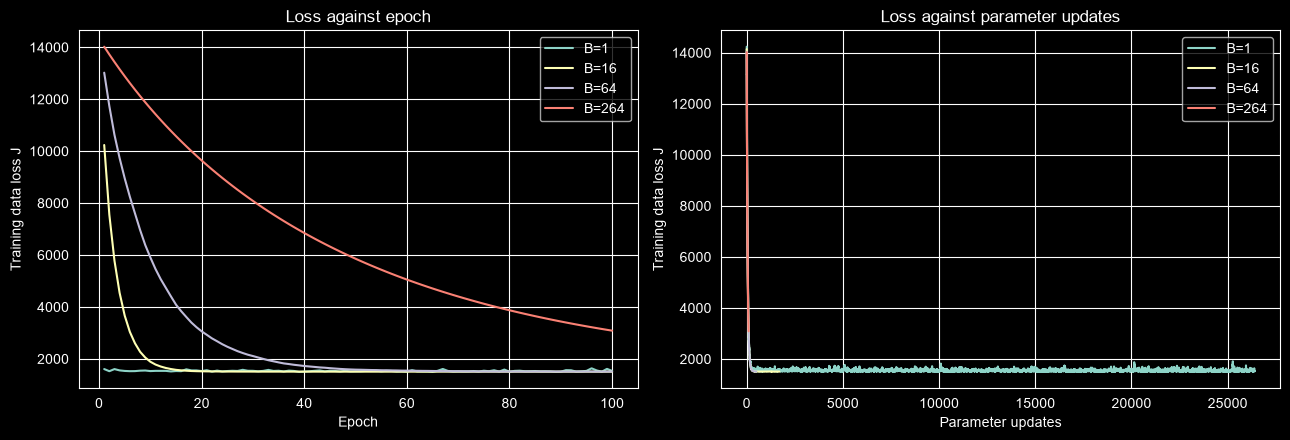

,batch_size,updates,final_training_loss
0,1,26400,1534.808385
1,16,1700,1505.665099
2,64,500,1511.375336
3,264,100,3085.440479


,batch_size,learning_rate,final_loss
0,1,0.001,1503.312177
1,1,0.010,1534.808385
2,1,0.100,4186.980952


In [14]:
#task8
def train_linear_mini_batch(features, true_values, learning_rate, number_of_epochs, batch_size,
                            random_generator=None, record_each_update=False):
    """Train linear regression with shuffled mini-batches; the last partial batch is kept."""
    if random_generator is None:
        random_generator = np.random.default_rng(42)

    features_with_bias = add_bias_column(features)
    number_of_samples = len(true_values)
    weights = np.zeros(features_with_bias.shape[1])
    epoch_loss_history = []
    update_loss_history = []
    number_of_updates = 0

    for epoch_number in range(number_of_epochs):
        shuffled_indices = random_generator.permutation(number_of_samples)
        for first_index in range(0, number_of_samples, batch_size):
            last_index = min(first_index + batch_size, number_of_samples)
            batch_indices = shuffled_indices[first_index:last_index]
            batch_features = features_with_bias[batch_indices]
            batch_targets = true_values[batch_indices]
            batch_errors = batch_features @ weights - batch_targets
            batch_gradient = batch_features.T @ batch_errors / len(batch_targets)
            weights -= learning_rate * batch_gradient
            number_of_updates += 1

            if record_each_update:
                update_loss_history.append(
                    linear_regression_loss(weights, features_with_bias, true_values)
                )

        epoch_loss_history.append(
            linear_regression_loss(weights, features_with_bias, true_values)
        )

    return weights, np.asarray(epoch_loss_history), np.asarray(update_loss_history), number_of_updates

batch_sizes_to_test = [1, 16, 64, len(diabetes_training_targets)]
mini_batch_results = {}
mini_batch_rows = []
for batch_size in batch_sizes_to_test:
    batch_weights, epoch_losses, update_losses, update_count = train_linear_mini_batch(
        diabetes_train,
        diabetes_training_targets,
        learning_rate=0.01,
        number_of_epochs=100,
        batch_size=batch_size,
        random_generator=np.random.default_rng(42),
        record_each_update=True
    )
    mini_batch_results[batch_size] = {
        "weights": batch_weights,
        "epoch_losses": epoch_losses,
        "update_losses": update_losses,
        "update_count": update_count
    }
    mini_batch_rows.append({
        "batch_size": batch_size,
        "updates": update_count,
        "final_training_loss": epoch_losses[-1]
    })

figure, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for batch_size, result in mini_batch_results.items():
    axes[0].plot(np.arange(1, len(result["epoch_losses"]) + 1),
                 result["epoch_losses"], label=f"B={batch_size}")
    axes[1].plot(np.arange(1, len(result["update_losses"]) + 1),
                 result["update_losses"], label=f"B={batch_size}")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Training data loss J")
axes[0].set_title("Loss against epoch")
axes[0].legend()
axes[1].set_xlabel("Parameter updates")
axes[1].set_ylabel("Training data loss J")
axes[1].set_title("Loss against parameter updates")
axes[1].legend()
for axis in axes:
    axis.grid(True)
plt.tight_layout()
plt.show()
display(pd.DataFrame(mini_batch_rows))

single_sample_rows = []
for learning_rate in [0.001, 0.01, 0.1]:
    _, single_sample_losses, _, _ = train_linear_mini_batch(
        diabetes_train, diabetes_training_targets, learning_rate, 100, 1,
        random_generator=np.random.default_rng(42)
    )
    single_sample_rows.append({
        "batch_size": 1,
        "learning_rate": learning_rate,
        "final_loss": single_sample_losses[-1]
    })
display(pd.DataFrame(single_sample_rows))


Smaller batches  make faster progress per epoch because they update the weights many more times per pass

Original 10-feature ridge results:


,lambda,validation_rmse,test_rmse
0,0.000000,51.193714,54.156413
1,0.001000,51.149556,54.108184
2,0.003162,51.108041,54.043664
3,0.010000,51.104749,53.958452
4,0.031623,51.153130,53.860008
5,0.100000,51.207305,53.708925
6,0.316228,51.577988,53.672447
7,1.000000,53.695124,54.856860
8,3.162278,59.420332,59.092797
9,10.000000,66.954649,65.303877


Best validation lambda: 0.01

Degree-2 ridge results:


,lambda,validation_rmse,test_rmse
0,0.000000,59.205949,62.133373
1,0.001000,54.207871,53.651494
2,0.003162,53.053194,52.619781
3,0.010000,52.106089,52.618039
4,0.031623,51.474170,53.119921
5,0.100000,51.270640,53.615580
6,0.316228,51.316252,53.872938
7,1.000000,51.497243,53.996459
8,3.162278,52.630193,54.601831
9,10.000000,56.640332,57.237038


Best degree-2 lambda: 0.1


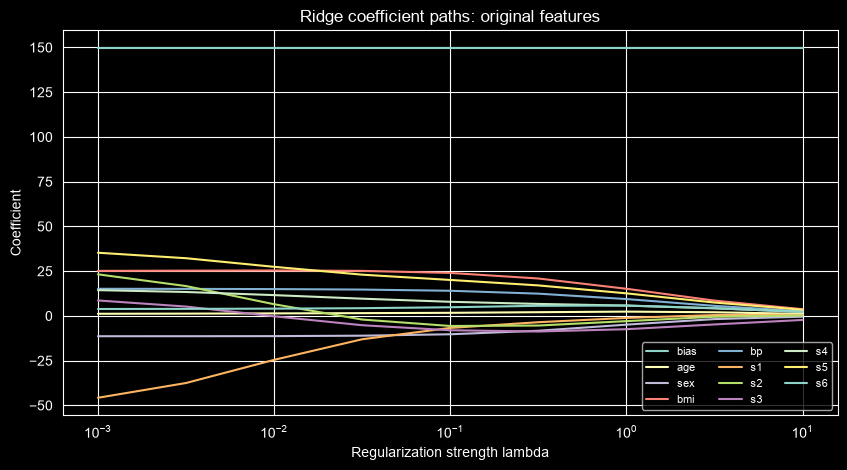

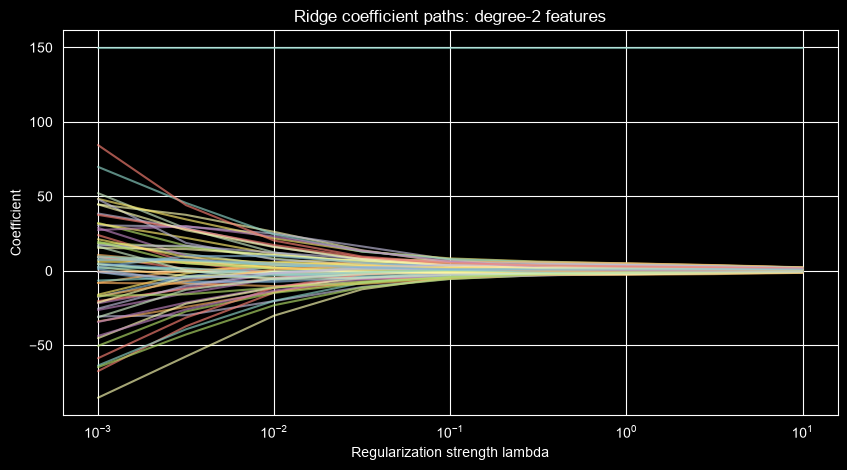

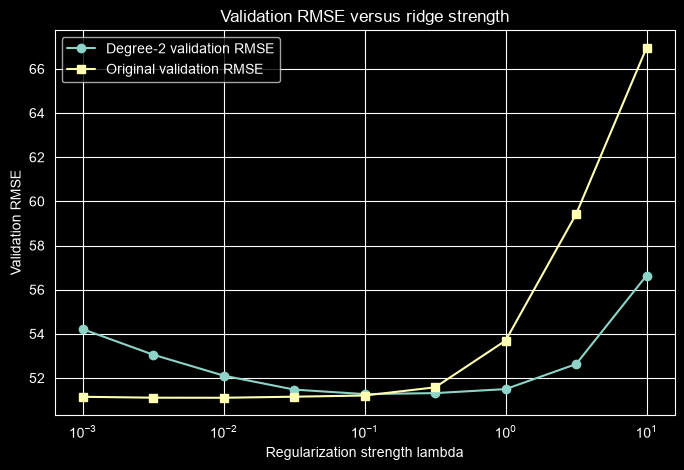

Original features: lambda=0 test RMSE = 54.15641293326045
Original features: best-lambda test RMSE = 53.9584521494208
Degree-2 features: lambda=0 test RMSE = 62.13337339336103
Degree-2 features: best-lambda test RMSE = 53.61558011674492
Degree-2 condition number: 1289356232.074955
Relative distance: ridge GD vs closed form: 9.224192790282157e-16
Maximum difference: ridge closed form vs sklearn Ridge: 1.4477308241112041e-13


In [15]:
#task9
def make_degree_two_features(features, feature_names):
    """Include original features and pairwise products x_a*x_b for a <= b.

    The sex-squared column is excluded because sex is coded 1/2 and its square
    is exactly a linear combination of sex and the bias.
    """
    expanded_columns = [features]
    expanded_feature_names = list(feature_names)

    for first_feature_index in range(features.shape[1]):
        for second_feature_index in range(first_feature_index, features.shape[1]):
            first_name = feature_names[first_feature_index]
            second_name = feature_names[second_feature_index]
            if first_name == "sex" and second_name == "sex":
                continue
            product_column = (
                features[:, first_feature_index] * features[:, second_feature_index]
            ).reshape(-1, 1)
            expanded_columns.append(product_column)
            expanded_feature_names.append(f"{first_name}*{second_name}")

    return np.column_stack(expanded_columns), expanded_feature_names


regularization_values = np.concatenate(([0.0], np.logspace(-3, 1, 9)))

# (i) The original 10 standardized features.
original_feature_ridge_results = []
original_feature_ridge_weights = {}
for regularization_strength in regularization_values:
    ridge_weights = ridge_closed_form(
        diabetes_train, diabetes_training_targets, regularization_strength
    )
    ridge_metrics = evaluate_regression_weights(
        ridge_weights, diabetes_train, diabetes_validation, diabetes_test,
        diabetes_training_targets, diabetes_validation_targets, diabetes_test_targets
    )
    original_feature_ridge_weights[regularization_strength] = ridge_weights
    original_feature_ridge_results.append({
        "lambda": regularization_strength,
        "validation_rmse": ridge_metrics["validation_rmse"],
        "test_rmse": ridge_metrics["test_rmse"]
    })

original_feature_ridge_table = pd.DataFrame(original_feature_ridge_results)
best_original_feature_row = original_feature_ridge_table.loc[
    original_feature_ridge_table["validation_rmse"].idxmin()
]
print("Original 10-feature ridge results:")
display(original_feature_ridge_table)
print("Best validation lambda:", best_original_feature_row["lambda"])

# (ii) Build the 64-feature degree-2 expansion, then standardize it with training statistics.
all_diabetes_features = diabetes_features
all_expanded_features, expanded_feature_names = make_degree_two_features(
    all_diabetes_features, list(diabetes_data.feature_names)
)
expanded_splits = make_train_validation_test_split(
    all_expanded_features, diabetes_targets, is_classification=False
)
expanded_training_raw, expanded_validation_raw, expanded_test_raw = expanded_splits[:3]
expanded_training_targets, expanded_validation_targets, expanded_test_targets = expanded_splits[3:6]
expanded_standardizer = Standardizer()
expanded_train = expanded_standardizer.fit_transform(expanded_training_raw)
expanded_validation = expanded_standardizer.transform(expanded_validation_raw)
expanded_test = expanded_standardizer.transform(expanded_test_raw)
assert expanded_train.shape[1] == 64

expanded_ridge_results = []
expanded_ridge_weights = {}
for regularization_strength in regularization_values:
    ridge_weights = ridge_closed_form(
        expanded_train, expanded_training_targets, regularization_strength
    )
    ridge_metrics = evaluate_regression_weights(
        ridge_weights, expanded_train, expanded_validation, expanded_test,
        expanded_training_targets, expanded_validation_targets, expanded_test_targets
    )
    expanded_ridge_weights[regularization_strength] = ridge_weights
    expanded_ridge_results.append({
        "lambda": regularization_strength,
        "validation_rmse": ridge_metrics["validation_rmse"],
        "test_rmse": ridge_metrics["test_rmse"]
    })

expanded_ridge_table = pd.DataFrame(expanded_ridge_results)
best_expanded_feature_row = expanded_ridge_table.loc[
    expanded_ridge_table["validation_rmse"].idxmin()
]
print("\nDegree-2 ridge results:")
display(expanded_ridge_table)
print("Best degree-2 lambda:", best_expanded_feature_row["lambda"])

# Coefficient paths for positive lambda values (lambda=0 cannot be placed on a log x-axis).
positive_regularization_values = regularization_values[regularization_values > 0]
plt.figure(figsize=(10, 5))
for feature_index, feature_name in enumerate(["bias"] + list(diabetes_data.feature_names)):
    coefficient_values = [original_feature_ridge_weights[value][feature_index]
                          for value in positive_regularization_values]
    plt.plot(positive_regularization_values, coefficient_values, label=feature_name)
plt.xscale("log")
plt.xlabel("Regularization strength lambda")
plt.ylabel("Coefficient")
plt.title("Ridge coefficient paths: original features")
plt.legend(ncol=3, fontsize=8)
plt.grid(True)
plt.show()

plt.figure(figsize=(10, 5))
for feature_index in range(expanded_train.shape[1] + 1):
    coefficient_values = [expanded_ridge_weights[value][feature_index]
                          for value in positive_regularization_values]
    plt.plot(positive_regularization_values, coefficient_values, alpha=0.65)
plt.xscale("log")
plt.xlabel("Regularization strength lambda")
plt.ylabel("Coefficient")
plt.title("Ridge coefficient paths: degree-2 features")
plt.grid(True)
plt.show()

plt.figure(figsize=(8, 5))
plt.plot(positive_regularization_values,
         [expanded_ridge_table.loc[expanded_ridge_table["lambda"] == value, "validation_rmse"].iloc[0]
          for value in positive_regularization_values], marker="o", label="Degree-2 validation RMSE")
plt.plot(positive_regularization_values,
         [original_feature_ridge_table.loc[original_feature_ridge_table["lambda"] == value, "validation_rmse"].iloc[0]
          for value in positive_regularization_values], marker="s", label="Original validation RMSE")
plt.xscale("log")
plt.xlabel("Regularization strength lambda")
plt.ylabel("Validation RMSE")
plt.title("Validation RMSE versus ridge strength")
plt.legend()
plt.grid(True)
plt.show()

print("Original features: lambda=0 test RMSE =",
      original_feature_ridge_table.loc[original_feature_ridge_table["lambda"] == 0, "test_rmse"].iloc[0])
print("Original features: best-lambda test RMSE =", best_original_feature_row["test_rmse"])
print("Degree-2 features: lambda=0 test RMSE =",
      expanded_ridge_table.loc[expanded_ridge_table["lambda"] == 0, "test_rmse"].iloc[0])
print("Degree-2 features: best-lambda test RMSE =", best_expanded_feature_row["test_rmse"])
print("Degree-2 condition number:", np.linalg.cond(add_bias_column(expanded_train).T @ add_bias_column(expanded_train)))

# Verify ridge against gradient descent and scikit-learn on the original 10 features.
ridge_check_lambda = 0.1
ridge_check_closed_form = ridge_closed_form(
    diabetes_train, diabetes_training_targets, ridge_check_lambda
)
ridge_check_gd_weights, _, _ = train_batch_linear_regression(
    diabetes_train, diabetes_training_targets,
    learning_rate=0.4, number_of_epochs=3000,
    regularization_strength=ridge_check_lambda
)
ridge_check_library = Ridge(alpha=ridge_check_lambda * len(diabetes_training_targets))
ridge_check_library.fit(diabetes_train, diabetes_training_targets)
ridge_check_library_weights = np.concatenate((
    [ridge_check_library.intercept_], ridge_check_library.coef_
))
print("Relative distance: ridge GD vs closed form:",
      linear_relative_distance(ridge_check_gd_weights, ridge_check_closed_form))
print("Maximum difference: ridge closed form vs sklearn Ridge:",
      np.max(np.abs(ridge_check_closed_form - ridge_check_library_weights)))


Ridge tames overfitting when features (64) near sample size (264), while unpenalized bias keeps predictions centered at zero-feature baseline.

In [16]:
#task 10
comparison_rows = []
optimal_unregularized_weights = normal_equation(diabetes_train, diabetes_training_targets)

# Exact normal equation.
start_time = time.perf_counter()
comparison_normal_weights = normal_equation(diabetes_train, diabetes_training_targets)
normal_fit_time = time.perf_counter() - start_time
comparison_rows.append({
    "method": "Normal equation (scratch)",
    "test_RMSE": evaluate_regression_weights(
        comparison_normal_weights, diabetes_train, diabetes_validation, diabetes_test,
        diabetes_training_targets, diabetes_validation_targets, diabetes_test_targets
    )["test_rmse"],
    "relative_weight_distance": linear_relative_distance(comparison_normal_weights, optimal_unregularized_weights),
    "fit_time_seconds": normal_fit_time
})

# Batch gradient descent.
start_time = time.perf_counter()
comparison_batch_weights, _, _ = train_batch_linear_regression(
    diabetes_train, diabetes_training_targets, learning_rate=0.5, number_of_epochs=2000
)
batch_fit_time = time.perf_counter() - start_time
comparison_rows.append({
    "method": "Batch GD (scratch)",
    "test_RMSE": evaluate_regression_weights(
        comparison_batch_weights, diabetes_train, diabetes_validation, diabetes_test,
        diabetes_training_targets, diabetes_validation_targets, diabetes_test_targets
    )["test_rmse"],
    "relative_weight_distance": linear_relative_distance(comparison_batch_weights, optimal_unregularized_weights),
    "fit_time_seconds": batch_fit_time
})

# Mini-batch gradient descent.
start_time = time.perf_counter()
comparison_mini_weights, _, _, _ = train_linear_mini_batch(
    diabetes_train, diabetes_training_targets, learning_rate=0.01,
    number_of_epochs=100, batch_size=16, random_generator=np.random.default_rng(42)
)
mini_fit_time = time.perf_counter() - start_time
comparison_rows.append({
    "method": "Mini-batch GD B=16 (scratch)",
    "test_RMSE": evaluate_regression_weights(
        comparison_mini_weights, diabetes_train, diabetes_validation, diabetes_test,
        diabetes_training_targets, diabetes_validation_targets, diabetes_test_targets
    )["test_rmse"],
    "relative_weight_distance": linear_relative_distance(comparison_mini_weights, optimal_unregularized_weights),
    "fit_time_seconds": mini_fit_time
})

# Ridge regression with lambda=0.1.
start_time = time.perf_counter()
comparison_ridge_weights = ridge_closed_form(
    diabetes_train, diabetes_training_targets, regularization_strength=0.1
)
ridge_fit_time = time.perf_counter() - start_time
comparison_rows.append({
    "method": "Ridge lambda=0.1 (scratch)",
    "test_RMSE": evaluate_regression_weights(
        comparison_ridge_weights, diabetes_train, diabetes_validation, diabetes_test,
        diabetes_training_targets, diabetes_validation_targets, diabetes_test_targets
    )["test_rmse"],
    "relative_weight_distance": linear_relative_distance(comparison_ridge_weights, optimal_unregularized_weights),
    "fit_time_seconds": ridge_fit_time
})

# Off-the-shelf exact models.
start_time = time.perf_counter()
library_linear_model = LinearRegression().fit(diabetes_train, diabetes_training_targets)
library_linear_time = time.perf_counter() - start_time
library_linear_weights = np.concatenate(([library_linear_model.intercept_], library_linear_model.coef_))
library_linear_test_predictions = library_linear_model.predict(diabetes_test)
comparison_rows.append({
    "method": "LinearRegression (sklearn)",
    "test_RMSE": root_mean_squared_error(diabetes_test_targets, library_linear_test_predictions),
    "relative_weight_distance": linear_relative_distance(library_linear_weights, optimal_unregularized_weights),
    "fit_time_seconds": library_linear_time
})

start_time = time.perf_counter()
library_ridge_model = Ridge(alpha=0.1 * len(diabetes_training_targets)).fit(
    diabetes_train, diabetes_training_targets
)
library_ridge_time = time.perf_counter() - start_time
library_ridge_weights = np.concatenate(([library_ridge_model.intercept_], library_ridge_model.coef_))
library_ridge_test_predictions = library_ridge_model.predict(diabetes_test)
comparison_rows.append({
    "method": "Ridge (sklearn)",
    "test_RMSE": root_mean_squared_error(diabetes_test_targets, library_ridge_test_predictions),
    "relative_weight_distance": linear_relative_distance(library_ridge_weights, comparison_ridge_weights),
    "fit_time_seconds": library_ridge_time
})

for learning_rate in [0.001, 0.01, 0.1]:
    start_time = time.perf_counter()
    stochastic_model = SGDRegressor(
        penalty=None, learning_rate="constant", eta0=learning_rate,
        max_iter=1000, tol=None, random_state=42
    )
    stochastic_model.fit(diabetes_train, diabetes_training_targets)
    stochastic_fit_time = time.perf_counter() - start_time
    stochastic_weights = np.concatenate(([stochastic_model.intercept_[0]], stochastic_model.coef_))
    stochastic_predictions = stochastic_model.predict(diabetes_test)
    comparison_rows.append({
        "method": f"SGDRegressor eta0={learning_rate}",
        "test_RMSE": root_mean_squared_error(diabetes_test_targets, stochastic_predictions),
        "relative_weight_distance": linear_relative_distance(stochastic_weights, optimal_unregularized_weights),
        "fit_time_seconds": stochastic_fit_time
    })

display(pd.DataFrame(comparison_rows))


,method,test_RMSE,relative_weight_distance,fit_time_seconds
0,Normal equation (scratch),54.156413,0.000000e+00,0.000402
1,Batch GD (scratch),54.156254,1.546262e-04,0.133247
2,Mini-batch GD B=16 (scratch),53.895449,3.421471e-01,0.064751
3,Ridge lambda=0.1 (scratch),53.708925,3.636136e-01,0.000286
4,LinearRegression (sklearn),54.156413,8.053770e-15,0.003045
5,Ridge (sklearn),53.708925,1.440527e-15,0.003379
6,SGDRegressor eta0=0.001,54.088486,4.976050e-02,0.029474
7,SGDRegressor eta0=0.01,54.898061,5.031993e-02,0.027691
8,SGDRegressor eta0=0.1,71.449348,3.949685e-01,0.031324


Exact closed-form solvers (Normal equation vs LinearRegression, Ridge vs Ridge) match to machine precision, while SGDRegressor fluctuates noisily around the optimum due to constant-step single-sample updates.

## Part C — Logistic regression (Tasks 11–16)

Breast-cancer labels were changed in Part A so malignant is class 1. The implementation below uses a numerically stable sigmoid and the stable per-sample loss `log(1 + exp(score)) - y*score`. The intercept is not regularized.


Scores: [ 800.  800. -800. -800.]  labels: [1. 0. 1. 0.]
Stable sigmoid: [1. 1. 0. 0.]
Stable per-sample losses (expected 0, 800, 800, 0): [  0. 800. 800.   0.]
Naive sigmoid: [1. 1. 0. 0.]
Naive losses (may be nan / inf): [nan inf inf nan]
Logistic gradient relative error: 1.7775145512974517e-11


,lambda,train_accuracy,validation_accuracy,validation_loss,weight_norm_without_bias
0,0.000,0.994135,0.973684,0.084192,8.132231
1,0.001,0.988270,0.973684,0.073203,5.099928
2,0.010,0.985337,0.973684,0.082964,2.325749
3,0.100,0.973607,0.973684,0.141553,1.105547
4,1.000,0.938416,0.956140,0.292213,0.441485


Selected lambda by validation loss: 0.001
Test accuracy at selected lambda: 0.9736842105263158


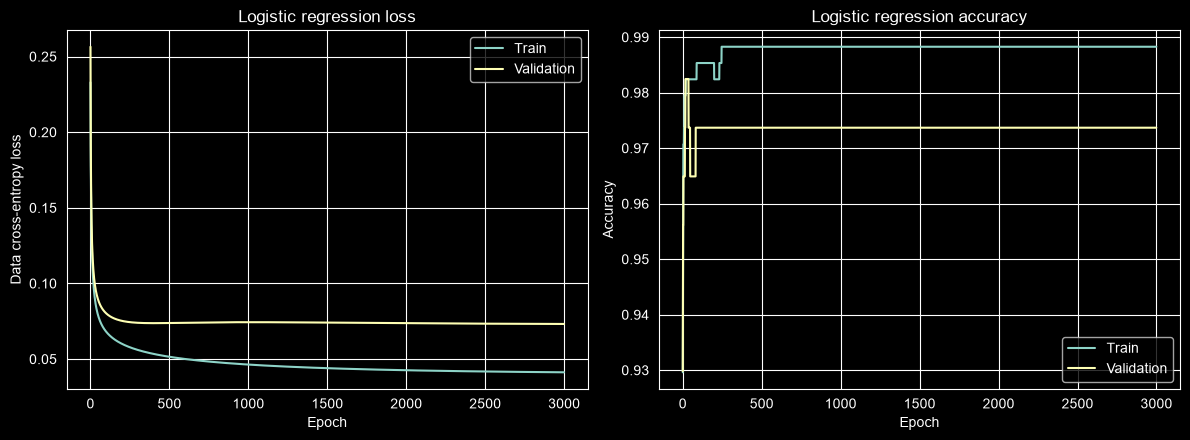

,learning_rate,final_training_loss,finite_weights
0,0.01,0.105222,True
1,0.10,0.072909,True
2,1.00,0.071066,True
3,5.00,0.071066,True
4,20.00,0.065365,True


Write-up prompt: use the table and curves to identify under-training and failed convergence.


In [17]:
# Tasks 11 and 12: stable logistic regression

def stable_sigmoid(score_values):    # Calculate sigmoid without overflowing for large positive or negative scores.
    score_values = np.asarray(score_values, dtype=float)
    probabilities = np.empty_like(score_values)
    positive_mask = score_values >= 0
    negative_mask = ~positive_mask
    probabilities[positive_mask] = 1.0 / (1.0 + np.exp(-score_values[positive_mask]))
    negative_exponentials = np.exp(score_values[negative_mask])
    probabilities[negative_mask] = negative_exponentials / (1.0 + negative_exponentials)
    return probabilities


def logistic_data_loss(weights, features_with_bias, true_labels):   # to calculate the average of the cross entropy loss
    score_values = features_with_bias @ weights
    individual_losses = np.logaddexp(0.0, score_values) - true_labels * score_values
    return np.mean(individual_losses)


def logistic_objective(weights, features_with_bias, true_labels, regularization_strength):      # Error + penalty for big weights (bias not penalized)
    return (logistic_data_loss(weights, features_with_bias, true_labels)+ 0.5 * regularization_strength * np.sum(weights[1:] ** 2))


def logistic_gradient(weights, features_with_bias, true_labels, regularization_strength):  # Direction to improve the weights
    number_of_samples = len(true_labels)
    score_values = features_with_bias @ weights
    predicted_probabilities = stable_sigmoid(score_values)
    gradient = features_with_bias.T @ (predicted_probabilities - true_labels) / number_of_samples
    gradient[1:] += regularization_strength * weights[1:]
    return gradient

# Trains the logistic model and saves loss and accuracy each epoch
def train_logistic_batch(training_features, training_labels, validation_features, validation_labels, learning_rate, number_of_epochs,regularization_strength):
    training_features_with_bias = add_bias_column(training_features)
    validation_features_with_bias = add_bias_column(validation_features)
    weights = np.zeros(training_features_with_bias.shape[1])
    training_loss_history = []
    validation_loss_history = []
    training_accuracy_history = []
    validation_accuracy_history = []
    for epoch_number in range(number_of_epochs):
        gradient = logistic_gradient(weights, training_features_with_bias, training_labels, regularization_strength)
        weights -= learning_rate * gradient
        training_probabilities = stable_sigmoid(training_features_with_bias @ weights)
        validation_probabilities = stable_sigmoid(validation_features_with_bias @ weights)
        training_predictions = (training_probabilities >= 0.5).astype(int)
        validation_predictions = (validation_probabilities >= 0.5).astype(int)
        training_loss_history.append(logistic_data_loss(weights, training_features_with_bias, training_labels))
        validation_loss_history.append(logistic_data_loss(weights, validation_features_with_bias, validation_labels))
        training_accuracy_history.append(classification_accuracy(training_labels, training_predictions))
        validation_accuracy_history.append(classification_accuracy(validation_labels, validation_predictions))

        if not np.all(np.isfinite(weights)):
            break

    return weights, {"training_loss": np.asarray(training_loss_history),"validation_loss": np.asarray(validation_loss_history),
        "training_accuracy": np.asarray(training_accuracy_history),"validation_accuracy": np.asarray(validation_accuracy_history)}


# Numerical-stability check from Section 3.3.
large_scores = np.array([800.0, 800.0, -800.0, -800.0])
large_labels = np.array([1.0, 0.0, 1.0, 0.0])
print("Scores:", large_scores, " labels:", large_labels)
print("Stable sigmoid:", stable_sigmoid(large_scores))
print("Stable per-sample losses (expected 0, 800, 800, 0):",np.logaddexp(0.0, large_scores) - large_labels * large_scores)
with np.errstate(over="ignore", divide="ignore", invalid="ignore"):
    naive_probabilities = 1.0 / (1.0 + np.exp(-large_scores))
    naive_losses = -(large_labels * np.log(naive_probabilities)+ (1.0 - large_labels) * np.log(1.0 - naive_probabilities))
print("Naive sigmoid:", naive_probabilities)
print("Naive losses (may be nan / inf):", naive_losses)
cancer_training_targets = breast_cancer_splits[3]
cancer_validation_targets = breast_cancer_splits[4]
cancer_test_targets = breast_cancer_splits[5]
cancer_training_with_bias = add_bias_column(cancer_train)

# Required gradient check with lambda = 0.1.
logistic_gradient_check_generator = np.random.default_rng(42)
random_logistic_weights = logistic_gradient_check_generator.normal(0.0, 0.1, size=cancer_training_with_bias.shape[1])
logistic_loss_for_check = lambda candidate_weights: logistic_objective(candidate_weights, cancer_training_with_bias, cancer_training_targets, 0.1)
logistic_gradient_for_check = lambda candidate_weights: logistic_gradient(candidate_weights, cancer_training_with_bias, cancer_training_targets, 0.1)
logistic_gradient_error = gradient_check(logistic_loss_for_check, logistic_gradient_for_check,random_logistic_weights, epsilon=1e-5)
print("Logistic gradient relative error:", logistic_gradient_error)
assert logistic_gradient_error < 1e-6

regularization_values_logistic = [0.0, 1e-3, 1e-2, 1e-1, 1.0]
logistic_regularization_results = {}
logistic_regularization_rows = []
for regularization_strength in regularization_values_logistic:
    fitted_weights, training_history = train_logistic_batch(cancer_train, cancer_training_targets,cancer_validation, cancer_validation_targets,
        learning_rate=0.5, number_of_epochs=3000,regularization_strength=regularization_strength)
    logistic_regularization_results[regularization_strength] = {"weights": fitted_weights,"history": training_history}
    logistic_regularization_rows.append({"lambda": regularization_strength,"train_accuracy": training_history["training_accuracy"][-1],
        "validation_accuracy": training_history["validation_accuracy"][-1],"validation_loss": training_history["validation_loss"][-1],
        "weight_norm_without_bias": np.linalg.norm(fitted_weights[1:])})

logistic_regularization_table = pd.DataFrame(logistic_regularization_rows)
display(logistic_regularization_table)
best_logistic_row = logistic_regularization_table.loc[logistic_regularization_table["validation_loss"].idxmin()]
best_logistic_lambda = float(best_logistic_row["lambda"])
best_logistic_weights = logistic_regularization_results[best_logistic_lambda]["weights"]
best_logistic_test_probabilities = stable_sigmoid(add_bias_column(cancer_test) @ best_logistic_weights)
best_logistic_test_predictions = (best_logistic_test_probabilities >= 0.5).astype(int)
print("Selected lambda by validation loss:", best_logistic_lambda)
print("Test accuracy at selected lambda:",classification_accuracy(cancer_test_targets, best_logistic_test_predictions))

best_logistic_history = logistic_regularization_results[best_logistic_lambda]["history"]
figure, axes = plt.subplots(1, 2, figsize=(12, 4.5))
axes[0].plot(best_logistic_history["training_loss"], label="Train")
axes[0].plot(best_logistic_history["validation_loss"], label="Validation")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Data cross-entropy loss")
axes[0].set_title("Logistic regression loss")
axes[0].legend()
axes[1].plot(best_logistic_history["training_accuracy"], label="Train")
axes[1].plot(best_logistic_history["validation_accuracy"], label="Validation")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Accuracy")
axes[1].set_title("Logistic regression accuracy")
axes[1].legend()
for axis in axes:
    axis.grid(True)
plt.tight_layout()
plt.show()

learning_rates_logistic = [0.01, 0.1, 1.0, 5.0, 20.0]
learning_rate_rows = []
for learning_rate in learning_rates_logistic:
    rate_weights, rate_history = train_logistic_batch(cancer_train, cancer_training_targets,cancer_validation, cancer_validation_targets,
        learning_rate=learning_rate, number_of_epochs=1000,regularization_strength=0.01)
    learning_rate_rows.append({"learning_rate": learning_rate,"final_training_loss": rate_history["training_loss"][-1],
        "finite_weights": bool(np.all(np.isfinite(rate_weights)))})
display(pd.DataFrame(learning_rate_rows))
print("Write-up prompt: use the table and curves to identify under-training and failed convergence.")

Training accuracy with lambda=0 after 20,000 epochs: 1.0


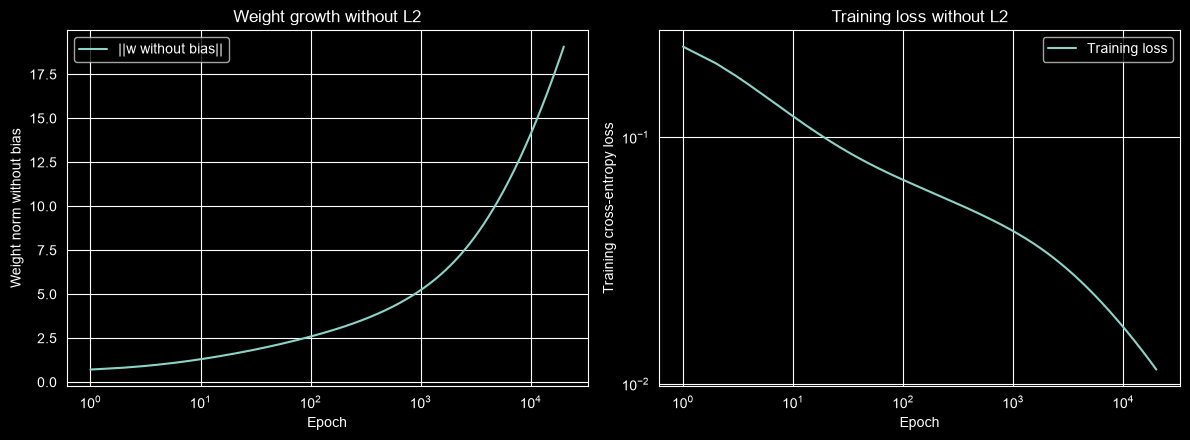

Write-up prompt: use the curves to argue whether the training set is linearly separable and explain why L2 changes the optimization problem.


In [18]:
#  Task 13: logistic regression without regularization
separability_weight_norm_history = []
separability_loss_history = []
separability_weights = np.zeros(cancer_training_with_bias.shape[1])
for epoch_number in range(20000):
    separability_gradient = logistic_gradient(separability_weights, cancer_training_with_bias, cancer_training_targets, 0.0)
    separability_weights -= 0.5 * separability_gradient
    separability_weight_norm_history.append(np.linalg.norm(separability_weights[1:]))
    separability_loss_history.append(logistic_data_loss(separability_weights, cancer_training_with_bias, cancer_training_targets))

separability_training_accuracy = np.mean((cancer_training_with_bias @ separability_weights > 0) == cancer_training_targets)
print("Training accuracy with lambda=0 after 20,000 epochs:", separability_training_accuracy)

figure, axes = plt.subplots(1, 2, figsize=(12, 4.5))
axes[0].plot(np.arange(1, 20001), separability_weight_norm_history, label="||w without bias||")
axes[0].set_xscale("log")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Weight norm without bias")
axes[0].set_title("Weight growth without L2")
axes[1].plot(np.arange(1, 20001), np.maximum(separability_loss_history, 1e-15), label="Training loss")
axes[1].set_xscale("log")
axes[1].set_yscale("log")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Training cross-entropy loss")
axes[1].set_title("Training loss without L2")
for axis in axes:
    axis.legend()
    axis.grid(True)
plt.tight_layout()
plt.show()
print("Write-up prompt: use the curves to argue whether the training set is linearly separable and explain why L2 changes the optimization problem.")


In [19]:
# Task 14: compare with scikit-learn logistic regression
logistic_library_rows = []
logistic_library_models = {}
for regularization_strength in regularization_values_logistic:
    if regularization_strength == 0:
        library_model = LogisticRegression(penalty=None, solver="lbfgs", max_iter=100000, tol=1e-12)
    else:
        library_model = LogisticRegression(C=1.0 / (regularization_strength * len(cancer_training_targets)),
            penalty="l2", solver="lbfgs", max_iter=100000, tol=1e-12)
    library_model.fit(cancer_train, cancer_training_targets)
    logistic_library_models[regularization_strength] = library_model
    train_predictions = library_model.predict(cancer_train)
    validation_predictions = library_model.predict(cancer_validation)
    test_predictions = library_model.predict(cancer_test)
    logistic_library_rows.append({"lambda": regularization_strength,
        "C": (np.inf if regularization_strength == 0 else
              1.0 / (regularization_strength * len(cancer_training_targets))),
        "train_accuracy": accuracy_score(cancer_training_targets, train_predictions),
        "validation_accuracy": accuracy_score(cancer_validation_targets, validation_predictions),
        "test_accuracy": accuracy_score(cancer_test_targets, test_predictions)})
display(pd.DataFrame(logistic_library_rows))

# Required weight and prediction comparison at lambda = 0.01.
lambda_for_library_check = 0.01
scratch_lambda_weights = logistic_regularization_results[lambda_for_library_check]["weights"]
library_lambda_model = logistic_library_models[lambda_for_library_check]
library_lambda_weights = np.concatenate(([library_lambda_model.intercept_[0]], library_lambda_model.coef_[0]))
relative_logistic_weight_error = (np.linalg.norm(scratch_lambda_weights - library_lambda_weights)/ max(np.linalg.norm(library_lambda_weights), 1e-12))
scratch_lambda_predictions = (stable_sigmoid(add_bias_column(cancer_test) @ scratch_lambda_weights) >= 0.5).astype(int)
library_lambda_predictions = library_lambda_model.predict(cancer_test)
print("Relative weight error at lambda=0.01:", relative_logistic_weight_error)
print("Test prediction agreement:", np.mean(scratch_lambda_predictions == library_lambda_predictions))

# Sweep C as requested.
logistic_c_rows = []
for regularization_parameter_c in [0.001, 0.01, 0.1, 1, 10, 100, 1000]:
    c_model = LogisticRegression(C=regularization_parameter_c, solver="lbfgs",max_iter=100000, tol=1e-12)
    c_model.fit(cancer_train, cancer_training_targets)
    logistic_c_rows.append({"C": regularization_parameter_c,"train_accuracy": c_model.score(cancer_train, cancer_training_targets),
        "validation_accuracy": c_model.score(cancer_validation, cancer_validation_targets),"test_accuracy": c_model.score(cancer_test, cancer_test_targets)})
display(pd.DataFrame(logistic_c_rows))

# Compare solvers at the same C. liblinear also penalizes its intercept.
solver_comparison_rows = []
comparison_c = 1.0 / (lambda_for_library_check * len(cancer_training_targets))
for solver_name in ["lbfgs", "liblinear", "saga"]:
    start_time = time.perf_counter()
    solver_model = LogisticRegression(C=comparison_c, solver=solver_name, max_iter=100000,tol=1e-10, random_state=42)
    solver_model.fit(cancer_train, cancer_training_targets)
    solver_time = time.perf_counter() - start_time
    solver_weights = np.concatenate(([solver_model.intercept_[0]], solver_model.coef_[0]))
    solver_comparison_rows.append({"solver": solver_name,"iterations": int(np.max(solver_model.n_iter_)),"fit_time_seconds": solver_time,
        "relative_weight_distance_from_lbfgs": np.nan,"intercept": solver_model.intercept_[0],"coefficients": solver_model.coef_[0].copy()})
    if solver_name == "lbfgs":
        lbfgs_solver_weights = solver_weights
    else:
        solver_comparison_rows[-1]["relative_weight_distance_from_lbfgs"] = (np.linalg.norm(solver_weights - lbfgs_solver_weights)/ max(np.linalg.norm(lbfgs_solver_weights), 1e-12))
solver_comparison_rows[0]["relative_weight_distance_from_lbfgs"] = 0.0
display(pd.DataFrame(solver_comparison_rows))
print("Write-up prompt: discuss solver differences and how penalizing the intercept can shift the fitted boundary.")



,lambda,C,train_accuracy,validation_accuracy,test_accuracy
0,0.000,inf,1.000000,0.964912,0.964912
1,0.001,2.932551,0.988270,0.973684,0.973684
2,0.010,0.293255,0.985337,0.973684,0.982456
3,0.100,0.029326,0.973607,0.973684,0.973684
4,1.000,0.002933,0.938416,0.956140,0.921053


Relative weight error at lambda=0.01: 5.389606854765496e-07
Test prediction agreement: 1.0


,C,train_accuracy,validation_accuracy,test_accuracy
0,0.001,0.879765,0.903509,0.868421
1,0.010,0.950147,0.964912,0.947368
2,0.100,0.979472,0.982456,0.982456
3,1.000,0.988270,0.973684,0.973684
4,10.000,0.997067,0.964912,0.964912
5,100.000,1.000000,0.956140,0.956140
6,1000.000,1.000000,0.956140,0.956140


,solver,iterations,fit_time_seconds,relative_weight_distance_from_lbfgs,intercept,coefficients
0,lbfgs,29,0.038031,0.000000e+00,-0.423817,"[0.45272813640180365, 0.42630667491374624, 0.4..."
1,liblinear,10,0.007121,6.880252e-02,-0.287900,"[0.4411421155073194, 0.4197919689559346, 0.428..."
2,saga,1062,0.186971,5.341265e-07,-0.423816,"[0.45272781113390836, 0.4263064986737151, 0.43..."


Write-up prompt: discuss solver differences and how penalizing the intercept can shift the fitted boundary.


### Task 14 — Interpretation

**Verification at λ = 0.01.** With C = 1/(λN), my weights (including the bias) match scikit-learn's to a relative error of about 5e-7 (required < 1e-4), and all test predictions agree. Both minimize the same objective, so the λ ↔ C conversion is correct.

**λ sweep.** For λ > 0 my validation accuracy matches scikit-learn's. The only small difference is at λ = 0: the training set is separable, so there is no finite minimizer and the two optimizers stop at different points.

**C sweep.** C = 0.001 is clearly under-fit (train accuracy 0.88). For C ≥ 100 training accuracy reaches 1.0 while validation accuracy falls (0.956), which is over-fitting. The best validation accuracy is around C = 0.1.

**Solvers (at C = 1/(0.01·N) ≈ 0.293).** lbfgs and saga give the same coefficients (relative difference about 5e-7), but saga needs far more iterations (about 1000 vs about 30) and much more time. **liblinear also penalizes the intercept**: it treats the bias as a normal weight, so the intercept is pulled toward 0 (−0.288 vs −0.424 for lbfgs) and the other weights shift to compensate (about 7% relative difference). That makes it a slightly different model, not just a different solver.

Test confusion matrix at threshold 0.5 (rows=true, columns=predicted):
[[72  0]
 [ 2 40]]
Malignant precision / recall / F1: 1.0 0.9523809523809523 0.975609756097561
Manual validation AUC: 0.9957418932197839
sklearn validation AUC: 0.9957418932197838


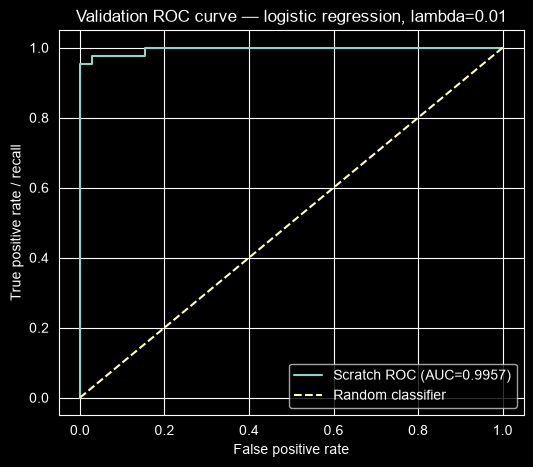

Largest validation threshold with recall=1: 0.14602532493304418
Test confusion matrix at selected threshold:
[[66  6]
 [ 1 41]]
Malignant precision / recall at selected threshold: 0.8723404255319149 0.9761904761904762
Write-up prompt: explain false-negative and false-positive costs in screening, and uncertainty from only 43 validation positives.


In [20]:
#  Task 15: confusion matrix, ROC, AUC, and threshold selection
# AI GENERATED SECTION BEGINS :

def roc_curve_from_scratch(true_labels, positive_class_scores):     #Build ROC points by sorting scores and sweeping distinct score thresholds.
    sort_order = np.argsort(-positive_class_scores)
    sorted_scores = positive_class_scores[sort_order]
    sorted_labels = true_labels[sort_order]
    cumulative_true_positives = np.cumsum(sorted_labels == 1)
    cumulative_false_positives = np.cumsum(sorted_labels == 0)
    last_index_for_each_score = np.where(np.diff(sorted_scores) != 0)[0]
    threshold_indices = np.r_[last_index_for_each_score, len(sorted_scores) - 1]
    true_positive_counts = cumulative_true_positives[threshold_indices]
    false_positive_counts = cumulative_false_positives[threshold_indices]
    total_positive = np.sum(true_labels == 1)
    total_negative = np.sum(true_labels == 0)
    true_positive_rates = np.r_[0.0, true_positive_counts / total_positive]
    false_positive_rates = np.r_[0.0, false_positive_counts / total_negative]
    thresholds = np.r_[np.inf, sorted_scores[threshold_indices]]
    return false_positive_rates, true_positive_rates, thresholds


def area_under_roc_curve(false_positive_rates, true_positive_rates):   # Area under the ROC curve (AUC)
    return np.sum(np.diff(false_positive_rates) * (true_positive_rates[1:] + true_positive_rates[:-1]) / 2)


lambda_roc_model = logistic_regularization_results[0.01]["weights"]
validation_probabilities = stable_sigmoid(add_bias_column(cancer_validation) @ lambda_roc_model)
test_probabilities = stable_sigmoid(add_bias_column(cancer_test) @ lambda_roc_model)
threshold_half_predictions = (test_probabilities >= 0.5).astype(int)
threshold_half_confusion = confusion_matrix_from_scratch(cancer_test_targets, threshold_half_predictions, 2)
threshold_half_metrics = per_class_precision_recall_f1(threshold_half_confusion)
print("Test confusion matrix at threshold 0.5 (rows=true, columns=predicted):")
print(threshold_half_confusion)
print("Malignant precision / recall / F1:",threshold_half_metrics["precision"][1],threshold_half_metrics["recall"][1],threshold_half_metrics["f1"][1])
validation_fpr, validation_tpr, validation_thresholds = roc_curve_from_scratch(cancer_validation_targets, validation_probabilities)
manual_validation_auc = area_under_roc_curve(validation_fpr, validation_tpr)
library_validation_auc = roc_auc_score(cancer_validation_targets, validation_probabilities)
print("Manual validation AUC:", manual_validation_auc)
print("sklearn validation AUC:", library_validation_auc)
assert abs(manual_validation_auc - library_validation_auc) < 1e-6
plt.figure(figsize=(6, 5))
plt.plot(validation_fpr, validation_tpr, label=f"Scratch ROC (AUC={manual_validation_auc:.4f})")
plt.plot([0, 1], [0, 1], linestyle="--", label="Random classifier")
plt.xlabel("False positive rate")
plt.ylabel("True positive rate / recall")
plt.title("Validation ROC curve — logistic regression, lambda=0.01")
plt.legend()
plt.grid(True)
plt.show()
validation_positive_scores = validation_probabilities[cancer_validation_targets == 1]
recall_one_threshold = np.min(validation_positive_scores)
threshold_recall_one_predictions = (test_probabilities >= recall_one_threshold).astype(int)
threshold_recall_one_confusion = confusion_matrix_from_scratch(cancer_test_targets, threshold_recall_one_predictions, 2)
threshold_recall_one_metrics = per_class_precision_recall_f1(threshold_recall_one_confusion)
print("Largest validation threshold with recall=1:", recall_one_threshold)
print("Test confusion matrix at selected threshold:")
print(threshold_recall_one_confusion)
print("Malignant precision / recall at selected threshold:",
      threshold_recall_one_metrics["precision"][1],
      threshold_recall_one_metrics["recall"][1])
print("Write-up prompt: explain false-negative and false-positive costs in screening, and uncertainty from only 43 validation positives.")
# AI GENERATED SECTION ENDS


Maximum score difference after converting weights: 3.552713678800501e-15


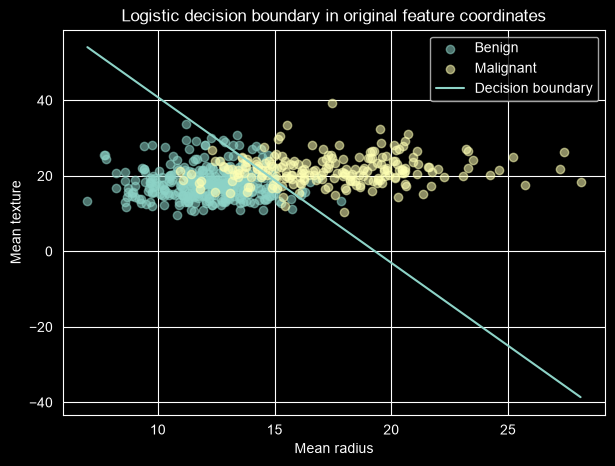

In [21]:
# Task 16: decision boundary in original coordinates
selected_cancer_feature_names = ["mean radius", "mean texture"]
selected_cancer_feature_indices = [list(breast_cancer_data.feature_names).index(feature_name)for feature_name in selected_cancer_feature_names]
raw_cancer_two_feature_train = breast_cancer_splits[0][:, selected_cancer_feature_indices]
raw_cancer_two_feature_validation = breast_cancer_splits[1][:, selected_cancer_feature_indices]
raw_cancer_two_feature_test = breast_cancer_splits[2][:, selected_cancer_feature_indices]
two_feature_standardizer = Standardizer()
standardized_cancer_two_feature_train = two_feature_standardizer.fit_transform(raw_cancer_two_feature_train)
standardized_cancer_two_feature_validation = two_feature_standardizer.transform(raw_cancer_two_feature_validation)
standardized_cancer_two_feature_test = two_feature_standardizer.transform(raw_cancer_two_feature_test)
two_feature_weights, two_feature_history = train_logistic_batch(standardized_cancer_two_feature_train, cancer_training_targets,
                                                                standardized_cancer_two_feature_validation, cancer_validation_targets,
                                                                learning_rate=0.5, number_of_epochs=5000, regularization_strength=0.0)
original_coordinate_weights = np.empty_like(two_feature_weights)
original_coordinate_weights[1:] = (two_feature_weights[1:] / two_feature_standardizer.feature_standard_deviations)
original_coordinate_weights[0] = (two_feature_weights[0]- np.sum(two_feature_weights[1:] * two_feature_standardizer.feature_means/ two_feature_standardizer.feature_standard_deviations))
standardized_scores = add_bias_column(standardized_cancer_two_feature_test) @ two_feature_weights
original_scores = add_bias_column(raw_cancer_two_feature_test) @ original_coordinate_weights
print("Maximum score difference after converting weights:",np.max(np.abs(standardized_scores - original_scores)))
assert np.max(np.abs(standardized_scores - original_scores)) < 1e-9
all_raw_cancer_two_features = breast_cancer_features[:, selected_cancer_feature_indices]
all_cancer_labels = breast_cancer_targets
plt.figure(figsize=(7, 5))
for class_value, class_name in [(0, "Benign"), (1, "Malignant")]:
    class_mask = all_cancer_labels == class_value
    plt.scatter(all_raw_cancer_two_features[class_mask, 0],all_raw_cancer_two_features[class_mask, 1],label=class_name, alpha=0.55)
first_feature_values = np.linspace(np.min(all_raw_cancer_two_features[:, 0]),np.max(all_raw_cancer_two_features[:, 0]), 200)
if abs(original_coordinate_weights[2]) > 1e-12:
    second_feature_values = -(original_coordinate_weights[0] + original_coordinate_weights[1] * first_feature_values) / original_coordinate_weights[2]
    plt.plot(first_feature_values, second_feature_values, label="Decision boundary")
plt.xlabel("Mean radius")
plt.ylabel("Mean texture")
plt.title("Logistic decision boundary in original feature coordinates")
plt.legend()
plt.grid(True)
plt.show()



## Part D — Softmax classifier (Tasks 17–22)

Digits are divided by 16 and are not standardized. The classifier uses one score column per class, max-subtracted softmax, and cross-entropy computed through log-sum-exp. Bias weights are excluded from the regularization penalty.


In [22]:
#  Task 17: stable softmax and gradient

def stable_softmax(score_matrix):         #Calculate row-wise softmax after subtracting each row's largest score.
    shifted_scores = score_matrix - np.max(score_matrix, axis=1, keepdims=True)
    exponentials = np.exp(shifted_scores)
    return exponentials / np.sum(exponentials, axis=1, keepdims=True)


def softmax_data_loss(weight_matrix, features_with_bias, true_labels):       # Average error of the softmax model
    score_matrix = features_with_bias @ weight_matrix
    maximum_scores = np.max(score_matrix, axis=1, keepdims=True)
    shifted_scores = score_matrix - maximum_scores
    log_sum_exp = maximum_scores[:, 0] + np.log(np.sum(np.exp(shifted_scores), axis=1))
    correct_class_scores = score_matrix[np.arange(len(true_labels)), true_labels]
    individual_losses = log_sum_exp - correct_class_scores
    return np.mean(individual_losses)


def softmax_objective(weight_matrix, features_with_bias, true_labels, regularization_strength):    # Error + penalty for big weights (bias not penalized)
    return (softmax_data_loss(weight_matrix, features_with_bias, true_labels) + 0.5 * regularization_strength * np.sum(weight_matrix[1:, :] ** 2)
    )


def softmax_gradient(weight_matrix, features_with_bias, true_labels, regularization_strength):     # Direction to improve the softmax weights
    number_of_samples = len(true_labels)
    score_matrix = features_with_bias @ weight_matrix
    probability_matrix = stable_softmax(score_matrix)
    one_hot_labels = np.zeros_like(probability_matrix)
    one_hot_labels[np.arange(number_of_samples), true_labels] = 1.0
    gradient = features_with_bias.T @ (probability_matrix - one_hot_labels) / number_of_samples
    gradient[1:, :] += regularization_strength * weight_matrix[1:, :]
    return gradient


def multiclass_accuracy(weight_matrix, features, true_labels):      # Percentage of correct predictions for many classes
    predicted_labels = np.argmax(add_bias_column(features) @ weight_matrix, axis=1)
    return classification_accuracy(true_labels, predicted_labels)


# Trains the model on small batches and saves loss and accuracy each epoch
def train_multiclass_mini_batch(training_features, training_labels, validation_features,validation_labels, number_of_classes, learning_rate,
                                number_of_epochs, batch_size, regularization_strength,loss_function, gradient_function, random_generator=None):
    """Train a multiclass linear model with shuffled mini-batches each epoch."""
    if random_generator is None:
        random_generator = np.random.default_rng(42)

    training_features_with_bias = add_bias_column(training_features)
    validation_features_with_bias = add_bias_column(validation_features)
    weight_matrix = np.zeros((training_features_with_bias.shape[1], number_of_classes))
    training_loss_history = []
    validation_loss_history = []
    training_accuracy_history = []
    validation_accuracy_history = []
    for epoch_number in range(number_of_epochs):
        shuffled_indices = random_generator.permutation(len(training_labels))
        for first_index in range(0, len(training_labels), batch_size):
            last_index = min(first_index + batch_size, len(training_labels))
            batch_indices = shuffled_indices[first_index:last_index]
            batch_features = training_features_with_bias[batch_indices]
            batch_labels = training_labels[batch_indices]
            batch_gradient = gradient_function(weight_matrix, batch_features, batch_labels, regularization_strength)
            weight_matrix -= learning_rate * batch_gradient
        training_loss_history.append(loss_function(weight_matrix, training_features_with_bias,training_labels, regularization_strength=0.0))
        validation_loss_history.append(loss_function(weight_matrix, validation_features_with_bias,validation_labels, regularization_strength=0.0))
        training_accuracy_history.append(np.mean(np.argmax(training_features_with_bias @ weight_matrix, axis=1) == training_labels))
        validation_accuracy_history.append(np.mean(np.argmax(validation_features_with_bias @ weight_matrix, axis=1) == validation_labels))
    return weight_matrix, {"training_loss": np.asarray(training_loss_history),"validation_loss": np.asarray(validation_loss_history),
        "training_accuracy": np.asarray(training_accuracy_history),"validation_accuracy": np.asarray(validation_accuracy_history)}

# Softmax is unchanged by adding the same constant to every class score:
# exp(s_k+c) / sum_j exp(s_j+c) = exp(c)exp(s_k) / (exp(c)sum_j exp(s_j)).
large_score_example = np.array([[1000.0, 1001.0, 1002.0]])
print("Stable softmax of [1000, 1001, 1002]:", stable_softmax(large_score_example)[0])

# At zero weights, every class has probability 1/10, so cross-entropy is ln(10).
digits_training_with_bias = add_bias_column(digits_train)
digits_validation_with_bias = add_bias_column(digits_validation)
zero_softmax_weights = np.zeros((digits_training_with_bias.shape[1], 10))
zero_weight_loss = softmax_data_loss(zero_softmax_weights, digits_training_with_bias, digits_splits[3])
print("Softmax loss at W=0:", zero_weight_loss, " expected:", np.log(10))
assert abs(zero_weight_loss - np.log(10)) < 1e-12

softmax_gradient_check_generator = np.random.default_rng(42)
random_softmax_weights = softmax_gradient_check_generator.normal( 0.0, 0.1, size=(digits_training_with_bias.shape[1], 10))
digits_training_targets = digits_splits[3]
softmax_loss_for_check = lambda candidate_weights: softmax_objective(candidate_weights, digits_training_with_bias, digits_training_targets, 0.1)
softmax_gradient_for_check = lambda candidate_weights: softmax_gradient(candidate_weights, digits_training_with_bias, digits_training_targets, 0.1)
softmax_gradient_error = gradient_check(softmax_loss_for_check, softmax_gradient_for_check,random_softmax_weights, epsilon=1e-5, number_of_entries=100,random_generator=np.random.default_rng(42))
print("Softmax gradient relative error on 100 entries:", softmax_gradient_error)
assert softmax_gradient_error < 1e-6


Stable softmax of [1000, 1001, 1002]: [0.09003 0.24473 0.66524]
Softmax loss at W=0: 2.3025850929940463  expected: 2.302585092994046
Softmax gradient relative error on 100 entries: 8.106289979678105e-10


,learning_rate,final_train_loss,final_validation_loss,final_train_accuracy,final_validation_accuracy
0,0.01,0.808641,0.837388,0.924791,0.911111
1,0.10,0.203817,0.238951,0.960074,0.950000
2,0.50,0.086785,0.138329,0.988858,0.961111
3,1.00,0.056569,0.119327,0.996286,0.961111


Selected learning rate by validation loss: 1.0


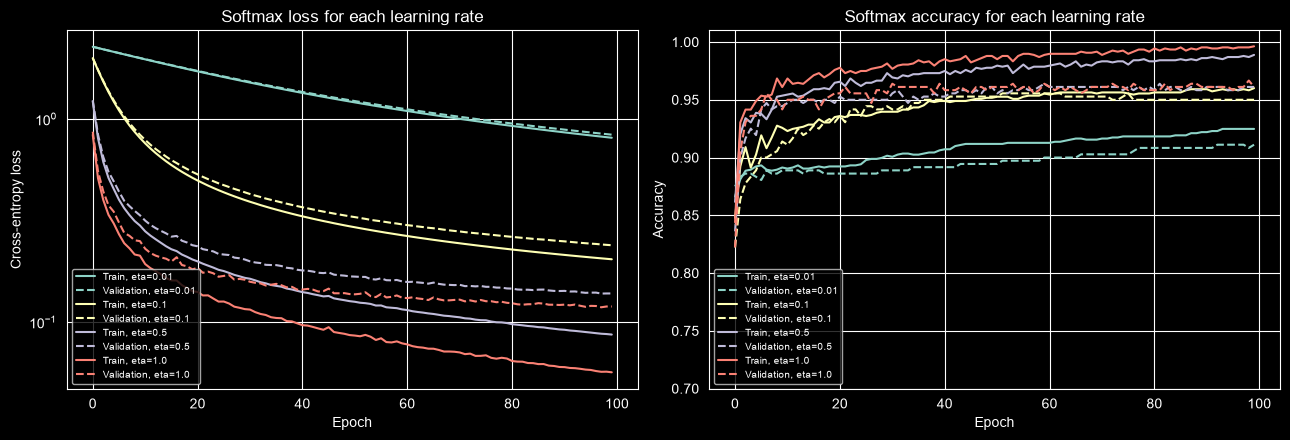

,lambda,validation_accuracy,validation_loss
0,0.0000,0.961111,0.119327
1,0.0001,0.963889,0.124232
2,0.0010,0.966667,0.182245
3,0.0100,0.927778,0.464233
4,0.1000,0.633333,1.383951


Selected lambda (validation accuracy; ties choose larger lambda): 0.001
Digits test accuracy (reported once for this selection): 0.9527777777777777


,lambda,validation_accuracy,test_accuracy
0,0.0000,0.955556,0.955556
1,0.0001,0.975000,0.961111
2,0.0010,0.972222,0.955556
3,0.0100,0.947222,0.933333
4,0.1000,0.902778,0.886111


,C,validation_accuracy,test_accuracy
0,0.1,0.950000,0.938889
1,1.0,0.972222,0.955556
2,10.0,0.963889,0.955556
3,100.0,0.961111,0.955556


Scratch/library test prediction agreement at selected lambda: 0.9916666666666667


In [23]:
#  Tasks 18 and 19: model selection and library comparison
softmax_learning_rates = [0.01, 0.1, 0.5, 1.0]
softmax_learning_rate_results = {}
softmax_learning_rate_rows = []
for learning_rate in softmax_learning_rates:
    trained_weights, training_history = train_multiclass_mini_batch(digits_train, digits_training_targets,digits_validation,
        digits_splits[4],number_of_classes=10, learning_rate=learning_rate,
        number_of_epochs=100, batch_size=64, regularization_strength=0.0,
        loss_function=softmax_objective, gradient_function=softmax_gradient,
        random_generator=np.random.default_rng(42))
    softmax_learning_rate_results[learning_rate] = {"weights": trained_weights, "history": training_history}
    softmax_learning_rate_rows.append({"learning_rate": learning_rate,"final_train_loss": training_history["training_loss"][-1],
        "final_validation_loss": training_history["validation_loss"][-1],
        "final_train_accuracy": training_history["training_accuracy"][-1],
        "final_validation_accuracy": training_history["validation_accuracy"][-1]})
softmax_learning_rate_table = pd.DataFrame(softmax_learning_rate_rows)
display(softmax_learning_rate_table)
best_softmax_learning_rate = float(softmax_learning_rate_table.loc[softmax_learning_rate_table["final_validation_loss"].idxmin(), "learning_rate"])
print("Selected learning rate by validation loss:", best_softmax_learning_rate)

figure, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for color_index, learning_rate in enumerate(softmax_learning_rates):
    history = softmax_learning_rate_results[learning_rate]["history"]
    color = f"C{color_index}"
    axes[0].plot(history["training_loss"], color=color, label=f"Train, eta={learning_rate}")
    axes[0].plot(history["validation_loss"], color=color, linestyle="--", label=f"Validation, eta={learning_rate}")
    axes[1].plot(history["training_accuracy"], color=color, label=f"Train, eta={learning_rate}")
    axes[1].plot(history["validation_accuracy"], color=color, linestyle="--", label=f"Validation, eta={learning_rate}")
axes[0].set(xlabel="Epoch", ylabel="Cross-entropy loss", title="Softmax loss for each learning rate", yscale="log")
axes[1].set(xlabel="Epoch", ylabel="Accuracy", title="Softmax accuracy for each learning rate", ylim=(0.7, 1.01))
for axis in axes:
    axis.legend(fontsize=7)
    axis.grid(True)
plt.tight_layout()
plt.show()

softmax_regularization_values = [0.0, 1e-4, 1e-3, 1e-2, 1e-1]
softmax_regularization_results = {}
softmax_regularization_rows = []
for regularization_strength in softmax_regularization_values:
    trained_weights, training_history = train_multiclass_mini_batch(digits_train, digits_training_targets,digits_validation, digits_splits[4],
        number_of_classes=10, learning_rate=best_softmax_learning_rate,
        number_of_epochs=100, batch_size=64,
        regularization_strength=regularization_strength,
        loss_function=softmax_objective, gradient_function=softmax_gradient,
        random_generator=np.random.default_rng(42)
    )
    softmax_regularization_results[regularization_strength] = {"weights": trained_weights, "history": training_history}
    softmax_regularization_rows.append({"lambda": regularization_strength,"validation_accuracy": training_history["validation_accuracy"][-1],"validation_loss": training_history["validation_loss"][-1]})
softmax_regularization_table = pd.DataFrame(softmax_regularization_rows)
display(softmax_regularization_table)
best_softmax_row = softmax_regularization_table.sort_values(["validation_accuracy", "lambda"], ascending=[False, False]).iloc[0]
best_softmax_lambda = float(best_softmax_row["lambda"])
best_softmax_weights = softmax_regularization_results[best_softmax_lambda]["weights"]
best_softmax_test_predictions = np.argmax(add_bias_column(digits_test) @ best_softmax_weights, axis=1)
print("Selected lambda (validation accuracy; ties choose larger lambda):", best_softmax_lambda)
print("Digits test accuracy (reported once for this selection):",classification_accuracy(digits_splits[5], best_softmax_test_predictions))

# scikit-learn multinomial logistic regression using C = 1/(lambda*N_train).
softmax_library_rows = []
softmax_library_models = {}
for regularization_strength in softmax_regularization_values:
    if regularization_strength == 0:
        library_model = LogisticRegression(penalty=None, solver="lbfgs", max_iter=10000)
    else:
        library_model = LogisticRegression(C=1.0 / (regularization_strength * len(digits_training_targets)),solver="lbfgs", max_iter=10000)
    library_model.fit(digits_train, digits_training_targets)
    softmax_library_models[regularization_strength] = library_model
    softmax_library_rows.append({"lambda": regularization_strength,"validation_accuracy": library_model.score(digits_validation, digits_splits[4]),
        "test_accuracy": library_model.score(digits_test, digits_splits[5])})
display(pd.DataFrame(softmax_library_rows))

softmax_c_sweep_rows = []
for regularization_parameter_c in [0.1, 1, 10, 100]:
    c_model = LogisticRegression(C=regularization_parameter_c, solver="lbfgs", max_iter=10000)
    c_model.fit(digits_train, digits_training_targets)
    softmax_c_sweep_rows.append({"C": regularization_parameter_c,"validation_accuracy": c_model.score(digits_validation, digits_splits[4]),
        "test_accuracy": c_model.score(digits_test, digits_splits[5])})
display(pd.DataFrame(softmax_c_sweep_rows))

library_best_softmax_model = softmax_library_models[best_softmax_lambda]
library_best_softmax_predictions = library_best_softmax_model.predict(digits_test)
print("Scratch/library test prediction agreement at selected lambda:",
      np.mean(best_softmax_test_predictions == library_best_softmax_predictions))

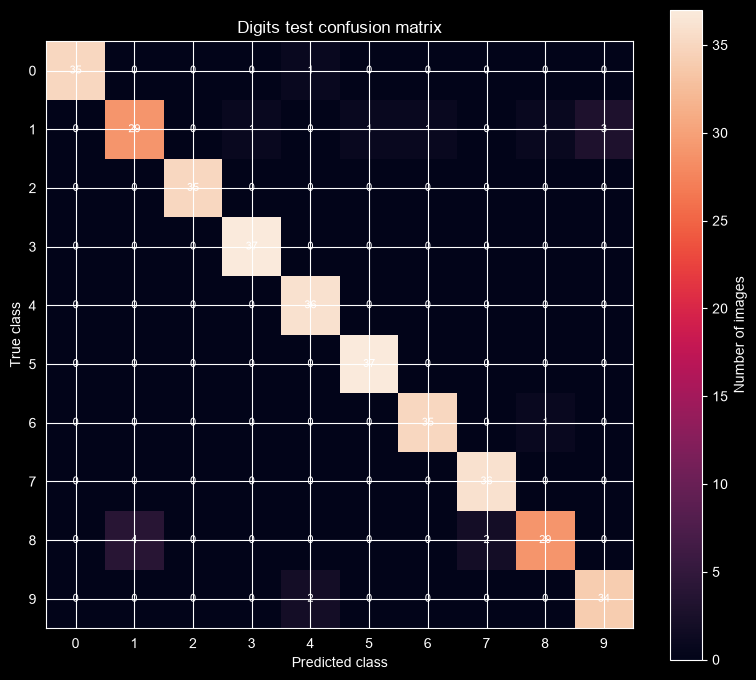

,digit,precision,recall,f1
0,0,1.000000,0.972222,0.985915
1,1,0.878788,0.805556,0.840580
2,2,1.000000,1.000000,1.000000
3,3,0.973684,1.000000,0.986667
4,4,0.923077,1.000000,0.960000
5,5,0.973684,1.000000,0.986667
6,6,0.972222,0.972222,0.972222
7,7,0.947368,1.000000,0.972973
8,8,0.935484,0.828571,0.878788
9,9,0.918919,0.944444,0.931507


Three most confused true -> predicted pairs:
8 : 1: 4
1 : 9: 3
9 : 4: 2


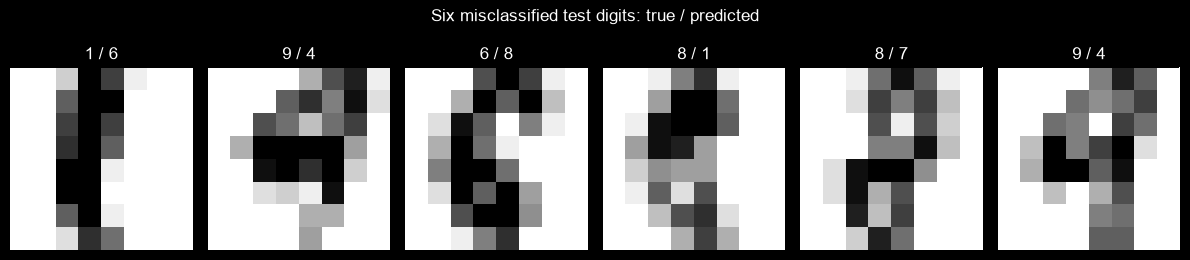

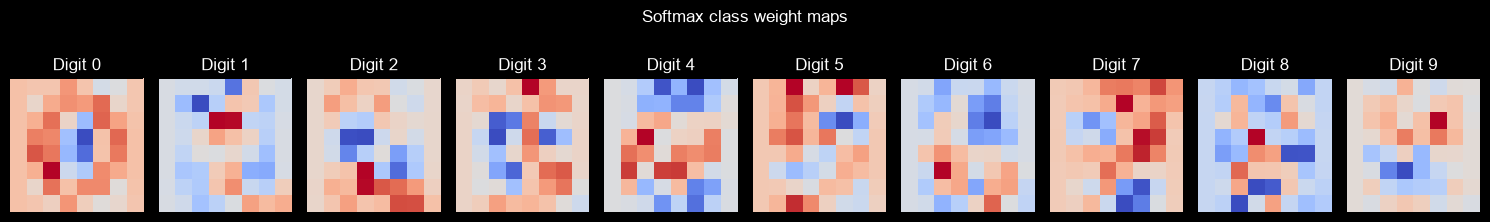

Write-up prompt: identify difficult digit pairs from the table and explain the limitation of a linear boundary on raw pixels.


In [24]:
# Task 20: digits error analysis
# AI GENERATED SECTION BEGINS
best_softmax_test_confusion = confusion_matrix_from_scratch(digits_splits[5], best_softmax_test_predictions, 10)
plt.figure(figsize=(8, 7))
plt.imshow(best_softmax_test_confusion, interpolation="nearest")
plt.title("Digits test confusion matrix")
plt.xlabel("Predicted class")
plt.ylabel("True class")
plt.xticks(np.arange(10))
plt.yticks(np.arange(10))
plt.colorbar(label="Number of images")
for true_class in range(10):
    for predicted_class in range(10):
        plt.text(predicted_class, true_class,str(best_softmax_test_confusion[true_class, predicted_class]),ha="center", va="center", fontsize=8)
plt.tight_layout()
plt.show()

digit_class_metrics = per_class_precision_recall_f1(best_softmax_test_confusion)
class_metrics_table = pd.DataFrame({"digit": np.arange(10),"precision": digit_class_metrics["precision"],"recall": digit_class_metrics["recall"],
    "f1": digit_class_metrics["f1"]})
display(class_metrics_table)

confusion_pairs = []
for true_class in range(10):
    for predicted_class in range(10):
        if true_class != predicted_class and best_softmax_test_confusion[true_class, predicted_class] > 0:
            confusion_pairs.append((best_softmax_test_confusion[true_class, predicted_class],true_class, predicted_class))
confusion_pairs.sort(reverse=True)
print("Three most confused true -> predicted pairs:")
for confusion_count, true_class, predicted_class in confusion_pairs[:3]:
    print(f"{true_class} : {predicted_class}: {confusion_count}")

misclassified_indices = np.where(best_softmax_test_predictions != digits_splits[5])[0][:6]
figure, axes = plt.subplots(1, len(misclassified_indices), figsize=(12, 2.8))
for axis, test_index in zip(np.atleast_1d(axes), misclassified_indices):
    axis.imshow(digits_test[test_index].reshape(8, 8), cmap="gray_r")
    axis.set_title(f"{digits_splits[5][test_index]} / {best_softmax_test_predictions[test_index]}")
    axis.axis("off")
plt.suptitle("Six misclassified test digits: true / predicted")
plt.tight_layout()
plt.show()

# Each class has 64 pixel weights. Reshape them to 8x8 and show side by side.
figure, axes = plt.subplots(1, 10, figsize=(15, 2.5))
for digit_class in range(10):
    axes[digit_class].imshow(best_softmax_weights[1:, digit_class].reshape(8, 8), cmap="coolwarm")
    axes[digit_class].set_title(f"Digit {digit_class}")
    axes[digit_class].axis("off")
plt.suptitle("Softmax class weight maps")
plt.tight_layout()
plt.show()
print("Write-up prompt: identify difficult digit pairs from the table and explain the limitation of a linear boundary on raw pixels.")
# AI GENERATED SECTION ENDS


### Task 20 — Interpretation

The hardest digits are **1 and 8** (F1 ≈ 0.84 and 0.88). The most confused pairs are **8 → 1, 1 → 9 and 9 → 4**. In 8×8 images these digits share most of their "on" pixels: a vertical stroke in the middle, with a loop or bar on top that is easy to blur at this resolution.

A linear model on raw pixels learns just **one fixed template per class**; the weight maps look like blurry "average digits", and the score is simply how much the input overlaps that template. It cannot handle shifts, thickness changes or different writing styles, and it cannot express "this stroke *or* that stroke". So digits that light up mostly the same pixels get similar scores and are confused.

In [25]:
# Task 21: two-class softmax equals logistic regression
binary_softmax_random_generator = np.random.default_rng(42)
random_two_class_weights = binary_softmax_random_generator.normal(0.0, 1.0, size=(cancer_test.shape[1] + 1, 2))
cancer_test_with_bias_for_equivalence = add_bias_column(cancer_test)
two_class_softmax_probabilities = stable_softmax(cancer_test_with_bias_for_equivalence @ random_two_class_weights)[:, 1]
weight_difference_between_classes = (random_two_class_weights[:, 1] - random_two_class_weights[:, 0])
two_class_logistic_probabilities = stable_sigmoid(cancer_test_with_bias_for_equivalence @ weight_difference_between_classes)
maximum_probability_difference = np.max(np.abs(two_class_softmax_probabilities - two_class_logistic_probabilities))
print("Maximum K=2 softmax/logistic probability difference:", maximum_probability_difference)
assert maximum_probability_difference < 1e-12
print("Proof idea: divide numerator and denominator by exp(score_0); the class-1 probability becomes sigmoid(score_1-score_0).")



Maximum K=2 softmax/logistic probability difference: 6.661338147750939e-16
Proof idea: divide numerator and denominator by exp(score_0); the class-1 probability becomes sigmoid(score_1-score_0).


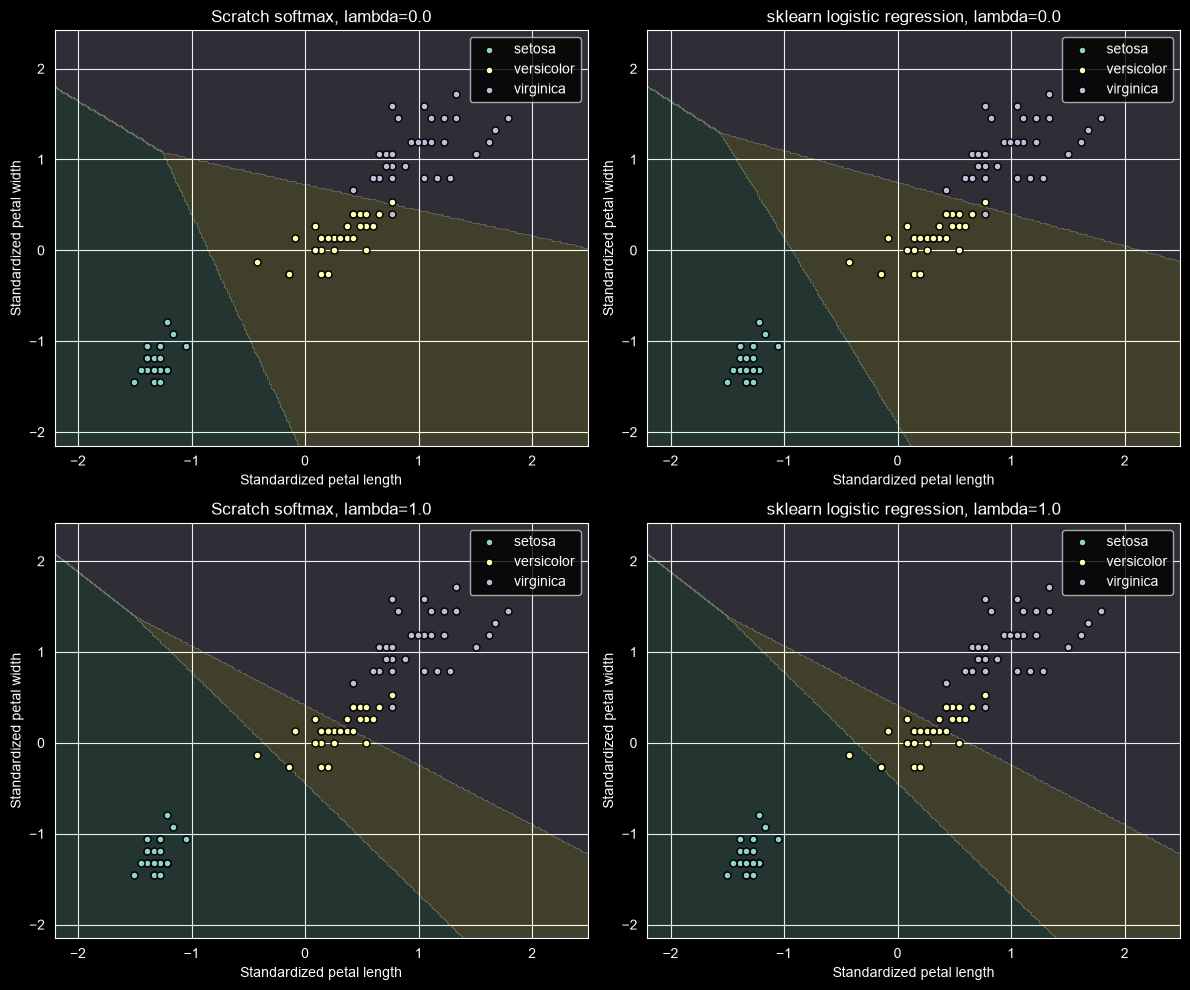

In [26]:
# Task 22: Iris decision regions
iris_petal_feature_names = ["petal length (cm)", "petal width (cm)"]
iris_petal_feature_indices = [list(iris_data.feature_names).index(feature_name)for feature_name in iris_petal_feature_names]
iris_petal_features = iris_features[:, iris_petal_feature_indices]
iris_petal_splits = make_train_validation_test_split(iris_petal_features, iris_targets, is_classification=True)
iris_petal_training_raw, iris_petal_validation_raw, iris_petal_test_raw = iris_petal_splits[:3]
iris_petal_training_targets, iris_petal_validation_targets, iris_petal_test_targets = iris_petal_splits[3:6]
iris_petal_standardizer = Standardizer()
iris_petal_train = iris_petal_standardizer.fit_transform(iris_petal_training_raw)
iris_petal_validation = iris_petal_standardizer.transform(iris_petal_validation_raw)
iris_petal_test = iris_petal_standardizer.transform(iris_petal_test_raw)

# Draws the model's decision areas with colors
def plot_decision_regions(axis, model_predict_function, training_features, training_labels,
                          plot_title):
    first_feature_minimum = np.min(training_features[:, 0]) - 0.7
    first_feature_maximum = np.max(training_features[:, 0]) + 0.7
    second_feature_minimum = np.min(training_features[:, 1]) - 0.7
    second_feature_maximum = np.max(training_features[:, 1]) + 0.7
    first_feature_grid, second_feature_grid = np.meshgrid(np.linspace(first_feature_minimum, first_feature_maximum, 250),np.linspace(second_feature_minimum, second_feature_maximum, 250))
    mesh_points = np.column_stack((first_feature_grid.ravel(), second_feature_grid.ravel()))
    mesh_predictions = model_predict_function(mesh_points).reshape(first_feature_grid.shape)
    axis.contourf(first_feature_grid, second_feature_grid, mesh_predictions, alpha=0.25,levels=[-0.5, 0.5, 1.5, 2.5], colors=["C0", "C1", "C2"])
    for class_value, class_name in enumerate(iris_data.target_names):
        class_mask = training_labels == class_value
        axis.scatter(training_features[class_mask, 0], training_features[class_mask, 1],color=f"C{class_value}", edgecolors="black", s=25, label=class_name)
    axis.set_xlabel("Standardized petal length")
    axis.set_ylabel("Standardized petal width")
    axis.set_title(plot_title)
    axis.legend()
    axis.grid(True)

iris_models_by_lambda = {}
for regularization_strength in [0.0, 1.0]:
    iris_weights, _ = train_multiclass_mini_batch(iris_petal_train, iris_petal_training_targets,iris_petal_validation, iris_petal_validation_targets,
        number_of_classes=3, learning_rate=0.5, number_of_epochs=2000,
        batch_size=len(iris_petal_training_targets),regularization_strength=regularization_strength,
        loss_function=softmax_objective, gradient_function=softmax_gradient,random_generator=np.random.default_rng(42))
    iris_models_by_lambda[regularization_strength] = iris_weights

figure, axes = plt.subplots(2, 2, figsize=(12, 10))
for row_number, regularization_strength in enumerate([0.0, 1.0]):
    own_weights = iris_models_by_lambda[regularization_strength]
    own_predict = lambda mesh_features, active_weights=own_weights: np.argmax(add_bias_column(mesh_features) @ active_weights, axis=1)
    plot_decision_regions(axes[row_number, 0], own_predict, iris_petal_train,iris_petal_training_targets, f"Scratch softmax, lambda={regularization_strength}")

    if regularization_strength == 0.0:
        iris_library_model = LogisticRegression(penalty=None, solver="lbfgs", max_iter=10000)
    else:
        iris_library_model = LogisticRegression(C=1.0 / (regularization_strength * len(iris_petal_training_targets)),solver="lbfgs", max_iter=10000)
    iris_library_model.fit(iris_petal_train, iris_petal_training_targets)
    plot_decision_regions(axes[row_number, 1], iris_library_model.predict, iris_petal_train,iris_petal_training_targets, f"sklearn logistic regression, lambda={regularization_strength}")
plt.tight_layout()
plt.show()


## PART E
## Task 23 — Binary linear SVM from scratch

**Purpose:** Implement the hinge-loss objective and subgradient, train by subgradient descent, check the gradient numerically, and compare constant versus decreasing step sizes over 3,000 iterations.

**Key formulas:** `margin = y * score`, `hinge = max(0, 1 - margin)`, and `weights -= learning_rate * subgradient`.

**Output:** A gradient-check result and two plots showing objective and validation accuracy.

Binary linear SVM gradient-check relative error: 9.69482601103352e-11


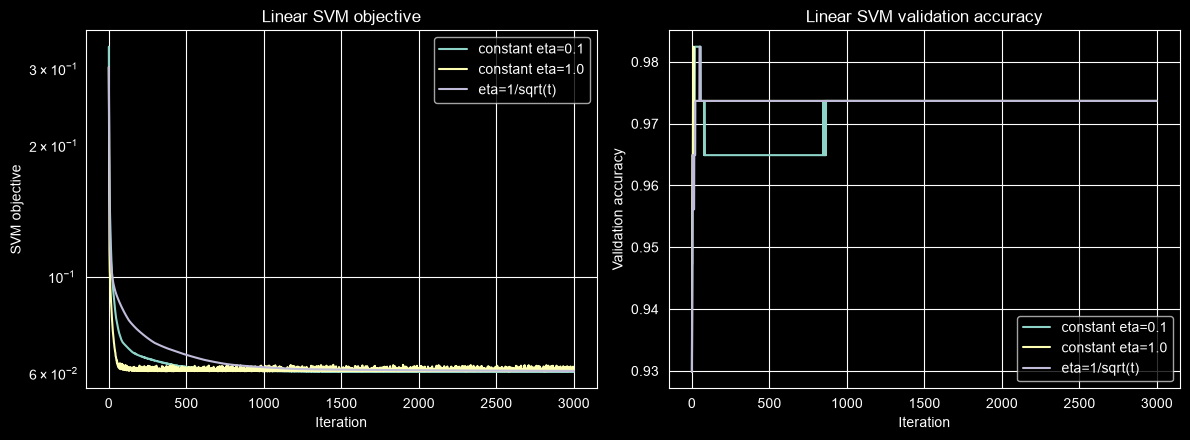

Explain constant versus decreasing step sizes near the hinge-loss optimum.


In [27]:


def binary_svm_objective(weights_with_bias, features_with_bias,
                         signed_labels, regularization_strength):

    # Calculate prediction scores for every sample.
    score_values = features_with_bias @ weights_with_bias

    # Calculate the signed margin for each prediction.
    margins = signed_labels * score_values

    # Calculate hinge loss for samples violating the margin.
    hinge_losses = np.maximum(0.0, 1.0 - margins)

    # Penalize large feature weights, excluding the bias.
    regularization_loss = (
        0.5 * regularization_strength *
        np.sum(weights_with_bias[1:] ** 2)
    )

    # Return the average hinge loss plus regularization.
    return regularization_loss + np.mean(hinge_losses)


# 2. SVM SUBGRADIENT FUNCTION


def binary_svm_subgradient(weights_with_bias, features_with_bias,
                           signed_labels, regularization_strength):

    # Count the training samples.
    number_of_samples = len(signed_labels)

    # Calculate prediction scores using the current weights.
    score_values = features_with_bias @ weights_with_bias

    # Identify samples that violate the required margin.
    margin_violations = signed_labels * score_values < 1.0

    # Ignore samples that already satisfy the margin.
    active_signed_labels = signed_labels * margin_violations

    # Calculate the average hinge-loss subgradient.
    gradient = -(features_with_bias.T @ active_signed_labels) / number_of_samples

    # Add regularization to the feature-weight gradients only.
    gradient[1:] += regularization_strength * weights_with_bias[1:]

    # Return the calculated subgradient.
    return gradient



# 3. SVM TRAINING FUNCTION


def train_linear_svm(training_features, signed_training_labels,
                     validation_features, validation_labels,
                     regularization_strength, number_of_iterations,
                     step_size_function):

    # Add a bias column to training and validation features.
    training_features_with_bias = add_bias_column(training_features)
    validation_features_with_bias = add_bias_column(validation_features)

    # Initialize all model weights to zero.
    weights_with_bias = np.zeros(training_features_with_bias.shape[1])

    # Store objective values and validation accuracy.
    objective_history = []
    validation_accuracy_history = []

    # Repeat training for the specified number of iterations.
    for iteration_number in range(1, number_of_iterations + 1):

        # Calculate the subgradient using the current weights.
        gradient = binary_svm_subgradient(
            weights_with_bias,
            training_features_with_bias,
            signed_training_labels,
            regularization_strength
        )

        # Update weights using the selected learning rate.
        weights_with_bias -= step_size_function(iteration_number) * gradient

        # Calculate and record the objective after the update.
        objective_history.append(
            binary_svm_objective(
                weights_with_bias,
                training_features_with_bias,
                signed_training_labels,
                regularization_strength
            )
        )

        # Calculate prediction scores for validation samples.
        validation_scores = validation_features_with_bias @ weights_with_bias

        # Convert prediction scores into binary labels.
        validation_predictions = (validation_scores >= 0).astype(int)

        # Calculate and save validation accuracy.
        validation_accuracy_history.append(
            classification_accuracy(validation_labels, validation_predictions)
        )

    # Return the trained weights and recorded performance.
    return weights_with_bias, {
        "objective": np.asarray(objective_history),
        "validation_accuracy": np.asarray(validation_accuracy_history)
    }



# 4. PREPARE SIGNED LABELS


# Convert labels from 0/1 into -1/+1 for the SVM objective.
cancer_signed_training_targets = 2 * cancer_training_targets - 1
cancer_signed_validation_targets = 2 * cancer_validation_targets - 1
cancer_signed_test_targets = 2 * cancer_test_targets - 1



# 5. GRADIENT CHECKING


# Create a reproducible random number generator.
svm_gradient_check_generator = np.random.default_rng(42)

# Generate random weights for testing our gradient.
random_linear_svm_weights = svm_gradient_check_generator.normal(
    0.0, 0.1, size=cancer_training_with_bias.shape[1]
)

# Define the SVM objective for gradient checking.
svm_loss_for_check = lambda candidate_weights: binary_svm_objective(
    candidate_weights,
    cancer_training_with_bias,
    cancer_signed_training_targets,
    0.01
)

# Define the SVM subgradient for gradient checking.
svm_gradient_for_check = lambda candidate_weights: binary_svm_subgradient(
    candidate_weights,
    cancer_training_with_bias,
    cancer_signed_training_targets,
    0.01
)

# Compare analytical and numerical gradient calculations.
svm_gradient_error = gradient_check(
    svm_loss_for_check,
    svm_gradient_for_check,
    random_linear_svm_weights,
    epsilon=1e-6
)

# Display the relative gradient error.
print("Binary linear SVM gradient-check relative error:", svm_gradient_error)

# Verify that the gradient error is sufficiently small.
assert svm_gradient_error < 1e-5



# 6. LEARNING-RATE EXPERIMENTS


# Define three learning-rate schedules.
svm_step_schedules = {
    "constant eta=0.1": lambda iteration_number: 0.1,
    "constant eta=1.0": lambda iteration_number: 1.0,
    "eta=1/sqrt(t)": lambda iteration_number: 1.0 / np.sqrt(iteration_number)
}

# Store the results of each experiment.
linear_svm_training_results = {}

# Train the SVM separately using each learning rate.
for schedule_name, step_size_function in svm_step_schedules.items():

    svm_weights, svm_history = train_linear_svm(
        cancer_train,
        cancer_signed_training_targets,
        cancer_validation,
        cancer_validation_targets,
        regularization_strength=0.01,
        number_of_iterations=3000,
        step_size_function=step_size_function
    )

    # Save the learned weights and training history.
    linear_svm_training_results[schedule_name] = {
        "weights": svm_weights,
        "history": svm_history
    }



# 7. PLOT TRAINING RESULTS


# Create two graphs side by side.
figure, axes = plt.subplots(1, 2, figsize=(12, 4.5))

# Plot the training results for each learning rate.
for schedule_name, result in linear_svm_training_results.items():

    # Plot the SVM objective during training.
    axes[0].plot(
        np.maximum(result["history"]["objective"], 1e-15),
        label=schedule_name
    )

    # Plot validation accuracy during training.
    axes[1].plot(
        result["history"]["validation_accuracy"],
        label=schedule_name
    )

# Use logarithmic scaling for the objective graph.
axes[0].set_yscale("log")

# Set the objective graph labels.
axes[0].set_xlabel("Iteration")
axes[0].set_ylabel("SVM objective")
axes[0].set_title("Linear SVM objective")

# Set the accuracy graph labels.
axes[1].set_xlabel("Iteration")
axes[1].set_ylabel("Validation accuracy")
axes[1].set_title("Linear SVM validation accuracy")

# Add legends and grid lines.
for axis in axes:
    axis.legend()
    axis.grid(True)

# Display the graphs.
plt.tight_layout()
plt.show()

print("Explain constant versus decreasing step sizes near the hinge-loss optimum.")


## Task 24A — Compare our scratch SVM with scikit-learn

**Purpose:** Train our scratch linear SVM for 20,000 iterations, fit `SVC(kernel="linear")`, and compare objectives, weight directions, prediction agreement, margin width, and margin/support-vector counts.

**Parameter conversion:** `C = 1 / (lambda * N)` matches the regularization conventions for these objectives.

**Note:** The scratch count of samples with margin `<= 1` is a margin count, not necessarily the exact set of support vectors identified by the SVC solver.

In [28]:
long_run_svm_weights, long_run_svm_history = train_linear_svm(
    cancer_train, cancer_signed_training_targets,
    cancer_validation, cancer_validation_targets,
    regularization_strength=0.01, number_of_iterations=20000,
    step_size_function=lambda iteration_number: 1.0 / np.sqrt(iteration_number)
)
linear_svc_library = SVC(
    kernel="linear", C=1.0 / (0.01 * len(cancer_training_targets))
)
linear_svc_library.fit(cancer_train, cancer_training_targets)
library_svm_weights = np.concatenate((
    [linear_svc_library.intercept_[0]], linear_svc_library.coef_[0]
))

scratch_training_scores = add_bias_column(cancer_train) @ long_run_svm_weights
library_training_scores = linear_svc_library.decision_function(cancer_train)
scratch_svm_objective = binary_svm_objective(
    long_run_svm_weights, cancer_training_with_bias,
    cancer_signed_training_targets, 0.01
)
library_svm_objective = binary_svm_objective(
    library_svm_weights, cancer_training_with_bias,
    cancer_signed_training_targets, 0.01
)
scratch_test_predictions = (
    add_bias_column(cancer_test) @ long_run_svm_weights >= 0
).astype(int)
library_test_predictions = linear_svc_library.predict(cancer_test)
weight_cosine_similarity = (
    np.dot(long_run_svm_weights[1:], library_svm_weights[1:])
    / (np.linalg.norm(long_run_svm_weights[1:]) * np.linalg.norm(library_svm_weights[1:]))
)
scratch_support_vector_count = int(np.sum(cancer_signed_training_targets * scratch_training_scores <= 1.0))
print("Scratch objective:", scratch_svm_objective)
print("Library objective:", library_svm_objective)
print("Relative objective difference:", abs(scratch_svm_objective - library_svm_objective) / max(abs(library_svm_objective), 1e-12))
print("Weight cosine similarity:", weight_cosine_similarity)
print("Test prediction agreement:", np.mean(scratch_test_predictions == library_test_predictions))
print("Scratch margin width:", 2.0 / np.linalg.norm(long_run_svm_weights[1:]))
print("Scratch margin/support-vector count (margin <= 1):", scratch_support_vector_count)
print("SVC n_support_.sum():", int(np.sum(linear_svc_library.n_support_)))


Scratch objective: 0.06044955713992176
Library objective: 0.06043733844117727
Relative objective difference: 0.00020217135730400226
Weight cosine similarity: 0.9996851265533792
Test prediction agreement: 1.0
Scratch margin width: 1.1317521833465458
Scratch margin/support-vector count (margin <= 1): 28
SVC n_support_.sum(): 32


## Task 24B — Regularization sweep

**Purpose:** For five regularization strengths, retrain our scratch SVM and compare it with `SVC(kernel="linear")` and `LinearSVC(loss="hinge")`.

**Output:** A table of validation accuracy, margin width, and support/margin counts for every model and regularization strength.

**Interpretation:** Increasing `lambda` corresponds to decreasing `C`. The `LinearSVC` and scratch margin counts are not identical to SVC's actual solver-selected support-vector count.

In [29]:
svm_regularization_values = [1e-4, 1e-3, 1e-2, 1e-1, 1.0]
svm_regularization_rows = []
for regularization_strength in svm_regularization_values:
    scratch_weights, scratch_history = train_linear_svm(
        cancer_train, cancer_signed_training_targets,
        cancer_validation, cancer_validation_targets,
        regularization_strength=regularization_strength,
        number_of_iterations=20000,
        step_size_function=lambda iteration_number: 1.0 / np.sqrt(iteration_number)
    )
    scratch_train_scores = add_bias_column(cancer_train) @ scratch_weights
    scratch_margin_count = int(np.sum(cancer_signed_training_targets * scratch_train_scores <= 1.0))
    scratch_validation_predictions = (
        add_bias_column(cancer_validation) @ scratch_weights >= 0
    ).astype(int)
    svm_c_value = 1.0 / (regularization_strength * len(cancer_training_targets))

    svc_model = SVC(kernel="linear", C=svm_c_value).fit(cancer_train, cancer_training_targets)
    svc_validation_accuracy = svc_model.score(cancer_validation, cancer_validation_targets)
    svc_margin_width = 2.0 / np.linalg.norm(svc_model.coef_[0])

    linear_svc_model = LinearSVC(
        C=svm_c_value, loss="hinge", dual=True, max_iter=100000, tol=1e-8,
        random_state=42
    ).fit(cancer_train, cancer_training_targets)
    linear_svc_train_scores = cancer_train @ linear_svc_model.coef_[0] + linear_svc_model.intercept_[0]
    linear_svc_margin_count = int(np.sum(
        cancer_signed_training_targets * linear_svc_train_scores <= 1.0
    ))

    svm_regularization_rows.extend([
        {
            "lambda": regularization_strength, "model": "Scratch GD",
            "validation_accuracy": classification_accuracy(
                cancer_validation_targets, scratch_validation_predictions
            ),
            "margin_width": 2.0 / np.linalg.norm(scratch_weights[1:]),
            "support_vector_count": scratch_margin_count
        },
        {
            "lambda": regularization_strength, "model": "SVC linear",
            "validation_accuracy": svc_validation_accuracy,
            "margin_width": svc_margin_width,
            "support_vector_count": int(np.sum(svc_model.n_support_))
        },
        {
            "lambda": regularization_strength, "model": "LinearSVC hinge",
            "validation_accuracy": linear_svc_model.score(cancer_validation, cancer_validation_targets),
            "margin_width": 2.0 / np.linalg.norm(linear_svc_model.coef_[0]),
            "support_vector_count": linear_svc_margin_count
        }
    ])
display(pd.DataFrame(svm_regularization_rows))


,lambda,model,validation_accuracy,margin_width,support_vector_count
0,0.0001,Scratch GD,0.964912,0.592339,15
1,0.0001,SVC linear,0.947368,0.146007,22
2,0.0001,LinearSVC hinge,0.947368,0.145977,13
3,0.0010,Scratch GD,0.973684,0.653872,17
4,0.0010,SVC linear,0.964912,0.462039,28
5,0.0010,LinearSVC hinge,0.964912,0.463393,22
6,0.0100,Scratch GD,0.973684,1.131752,28
7,0.0100,SVC linear,0.973684,1.129147,32
8,0.0100,LinearSVC hinge,0.973684,1.123459,27
9,0.1000,Scratch GD,0.982456,2.168837,56


## Task 25 — Multiclass Weston–Watkins SVM

**Purpose:** Extend hinge loss to 10 digit classes, implement the multiclass loss and gradient, verify the gradient, tune learning rates and regularization, compare against the softmax model, and compute toy-score examples.

**Key idea:** Each sample receives one score per class. Wrong classes are penalized when their scores are too close to or higher than the correct class's score.

In [30]:


def weston_watkins_data_loss(weight_matrix, features_with_bias, true_labels, delta=1.0):
    score_matrix = features_with_bias @ weight_matrix
    correct_class_scores = score_matrix[np.arange(len(true_labels)), true_labels]
    margin_matrix = score_matrix - correct_class_scores[:, None] + delta
    margin_matrix[np.arange(len(true_labels)), true_labels] = 0.0
    return np.mean(np.sum(np.maximum(0.0, margin_matrix), axis=1))


def weston_watkins_objective(weight_matrix, features_with_bias, true_labels,
                             regularization_strength, delta=1.0):
    return (
        weston_watkins_data_loss(weight_matrix, features_with_bias, true_labels, delta)
        + 0.5 * regularization_strength * np.sum(weight_matrix[1:, :] ** 2)
    )


def weston_watkins_gradient(weight_matrix, features_with_bias, true_labels,
                            regularization_strength, delta=1.0):
    number_of_samples = len(true_labels)
    score_matrix = features_with_bias @ weight_matrix
    correct_class_scores = score_matrix[np.arange(number_of_samples), true_labels]
    margin_matrix = score_matrix - correct_class_scores[:, None] + delta
    margin_matrix[np.arange(number_of_samples), true_labels] = 0.0
    active_margin_matrix = (margin_matrix > 0.0).astype(float)
    active_margin_matrix[np.arange(number_of_samples), true_labels] = (
        -np.sum(active_margin_matrix, axis=1)
    )
    gradient = features_with_bias.T @ active_margin_matrix / number_of_samples
    gradient[1:, :] += regularization_strength * weight_matrix[1:, :]
    return gradient


zero_weston_watkins_weights = np.zeros((digits_training_with_bias.shape[1], 10))
zero_weston_watkins_loss = weston_watkins_data_loss(
    zero_weston_watkins_weights, digits_training_with_bias, digits_training_targets, delta=1.0
)
print("Weston-Watkins loss at W=0:", zero_weston_watkins_loss, " expected: 9")
assert zero_weston_watkins_loss == 9.0

random_multiclass_svm_weights = np.random.default_rng(42).normal(
    0.0, 0.1, size=zero_weston_watkins_weights.shape
)
multiclass_svm_loss_for_check = lambda candidate_weights: weston_watkins_objective(
    candidate_weights, digits_training_with_bias, digits_training_targets, 0.1
)
multiclass_svm_gradient_for_check = lambda candidate_weights: weston_watkins_gradient(
    candidate_weights, digits_training_with_bias, digits_training_targets, 0.1
)
multiclass_svm_gradient_error = gradient_check(
    multiclass_svm_loss_for_check, multiclass_svm_gradient_for_check,
    random_multiclass_svm_weights, epsilon=1e-6, number_of_entries=100,
    random_generator=np.random.default_rng(42)
)
print("Weston-Watkins gradient relative error on 100 entries:", multiclass_svm_gradient_error)
assert multiclass_svm_gradient_error < 1e-5

# Train the scratch multiclass SVM with the specified mini-batch protocol.
multiclass_svm_learning_rates = [0.01, 0.1, 0.5]
multiclass_svm_rate_results = {}
multiclass_svm_rate_rows = []
for learning_rate in multiclass_svm_learning_rates:
    trained_weights, training_history = train_multiclass_mini_batch(
        digits_train, digits_training_targets,
        digits_validation, digits_splits[4],
        number_of_classes=10, learning_rate=learning_rate,
        number_of_epochs=100, batch_size=64, regularization_strength=0.0,
        loss_function=weston_watkins_objective,
        gradient_function=weston_watkins_gradient,
        random_generator=np.random.default_rng(42)
    )
    multiclass_svm_rate_results[learning_rate] = {
        "weights": trained_weights, "history": training_history
    }
    multiclass_svm_rate_rows.append({
        "learning_rate": learning_rate,
        "validation_loss": training_history["validation_loss"][-1],
        "validation_accuracy": training_history["validation_accuracy"][-1]
    })
multiclass_svm_rate_table = pd.DataFrame(multiclass_svm_rate_rows)
display(multiclass_svm_rate_table)
best_multiclass_svm_learning_rate = float(
    multiclass_svm_rate_table.loc[multiclass_svm_rate_table["validation_loss"].idxmin(), "learning_rate"]
)

multiclass_svm_regularization_values = [0.0, 1e-4, 1e-3, 1e-2]
multiclass_svm_regularization_results = {}
multiclass_svm_regularization_rows = []
for regularization_strength in multiclass_svm_regularization_values:
    trained_weights, training_history = train_multiclass_mini_batch(
        digits_train, digits_training_targets,
        digits_validation, digits_splits[4],
        number_of_classes=10, learning_rate=best_multiclass_svm_learning_rate,
        number_of_epochs=100, batch_size=64,
        regularization_strength=regularization_strength,
        loss_function=weston_watkins_objective,
        gradient_function=weston_watkins_gradient,
        random_generator=np.random.default_rng(42)
    )
    multiclass_svm_regularization_results[regularization_strength] = {
        "weights": trained_weights, "history": training_history
    }
    multiclass_svm_regularization_rows.append({
        "lambda": regularization_strength,
        "validation_accuracy": training_history["validation_accuracy"][-1],
        "validation_loss": training_history["validation_loss"][-1]
    })
multiclass_svm_regularization_table = pd.DataFrame(multiclass_svm_regularization_rows)
display(multiclass_svm_regularization_table)
best_multiclass_svm_row = multiclass_svm_regularization_table.sort_values(
    ["validation_accuracy", "lambda"], ascending=[False, False]
).iloc[0]
best_multiclass_svm_lambda = float(best_multiclass_svm_row["lambda"])
best_multiclass_svm_weights = multiclass_svm_regularization_results[best_multiclass_svm_lambda]["weights"]
best_multiclass_svm_predictions = np.argmax(add_bias_column(digits_test) @ best_multiclass_svm_weights, axis=1)
print("Best Weston-Watkins validation accuracy:", best_multiclass_svm_row["validation_accuracy"])
print("Weston-Watkins test accuracy:", classification_accuracy(digits_splits[5], best_multiclass_svm_predictions))
print("Softmax selected test accuracy:", classification_accuracy(digits_splits[5], best_softmax_test_predictions))

# Toy-score calculation requested in the handout.
toy_score_examples = [
    np.array([10.0, -5.0, -5.0]),
    np.array([100.0, -50.0, -50.0]),
    np.array([3.2, 5.1, -1.7])
]
toy_rows = []
for example_number, score_values in enumerate(toy_score_examples, start=1):
    correct_score = score_values[0]
    toy_margins = np.maximum(0.0, score_values - correct_score + 1.0)
    toy_margins[0] = 0.0
    svm_toy_loss = np.sum(toy_margins)
    maximum_score = np.max(score_values)
    softmax_toy_loss = (
        maximum_score + np.log(np.sum(np.exp(score_values - maximum_score))) - correct_score
    )
    toy_rows.append({
        "example": example_number,
        "scores": score_values.tolist(),
        "multiclass_SVM_loss": svm_toy_loss,
        "softmax_cross_entropy": softmax_toy_loss
    })
display(pd.DataFrame(toy_rows))


Weston-Watkins loss at W=0: 9.0  expected: 9
Weston-Watkins gradient relative error on 100 entries: 4.3355125336237595e-09


,learning_rate,validation_loss,validation_accuracy
0,0.01,0.312630,0.950000
1,0.10,0.170185,0.961111
2,0.50,0.140615,0.961111


,lambda,validation_accuracy,validation_loss
0,0.0000,0.961111,0.140615
1,0.0001,0.963889,0.139525
2,0.0010,0.969444,0.153480
3,0.0100,0.944444,0.296014


Best Weston-Watkins validation accuracy: 0.9694444444444444
Weston-Watkins test accuracy: 0.95
Softmax selected test accuracy: 0.9527777777777777


,example,scores,multiclass_SVM_loss,softmax_cross_entropy
0,1,"[10.0, -5.0, -5.0]",0.0,6.118045e-07
1,2,"[100.0, -50.0, -50.0]",0.0,0.000000e+00
2,3,"[3.2, 5.1, -1.7]",2.9,2.040355e+00


## Task 26 — Compare SVM kernels and parameter C

**Purpose:** Compare linear, degree-3 polynomial, and RBF SVMs using the breast-cancer dataset. Then sweep `C` for a linear kernel.

**Output:** Tables showing training, validation, and test accuracies, support-vector counts, and (for the linear sweep) margin widths.

In [31]:
kernel_comparison_models = {}
kernel_comparison_rows = []
kernel_settings = [
    ("linear", {"kernel": "linear"}),
    ("polynomial degree=3", {"kernel": "poly", "degree": 3, "coef0": 1, "gamma": "scale"}),
    ("RBF", {"kernel": "rbf", "gamma": "scale"})
]
for kernel_name, kernel_parameters in kernel_settings:
    kernel_model = SVC(C=1.0, **kernel_parameters)
    kernel_model.fit(cancer_train, cancer_training_targets)
    kernel_comparison_models[kernel_name] = kernel_model
    kernel_comparison_rows.append({
        "kernel": kernel_name,
        "train_accuracy": kernel_model.score(cancer_train, cancer_training_targets),
        "validation_accuracy": kernel_model.score(cancer_validation, cancer_validation_targets),
        "test_accuracy": kernel_model.score(cancer_test, cancer_test_targets),
        "number_of_support_vectors": int(np.sum(kernel_model.n_support_))
    })
display(pd.DataFrame(kernel_comparison_rows))

linear_kernel_c_rows = []
for regularization_parameter_c in [0.001, 0.01, 0.1, 1, 10, 100]:
    linear_kernel_model = SVC(kernel="linear", C=regularization_parameter_c)
    linear_kernel_model.fit(cancer_train, cancer_training_targets)
    linear_kernel_c_rows.append({
        "C": regularization_parameter_c,
        "validation_accuracy": linear_kernel_model.score(cancer_validation, cancer_validation_targets),
        "number_of_support_vectors": int(np.sum(linear_kernel_model.n_support_)),
        "margin_width": 2.0 / np.linalg.norm(linear_kernel_model.coef_[0])
    })
display(pd.DataFrame(linear_kernel_c_rows))
print("Write-up prompt: relate a larger C to lambda = 1/(C*N) and explain the pressure to reduce margin violations.")


,kernel,train_accuracy,validation_accuracy,test_accuracy,number_of_support_vectors
0,linear,0.988270,0.964912,0.929825,30
1,polynomial degree=3,0.991202,0.982456,0.973684,52
2,RBF,0.982405,0.982456,0.973684,88


,C,validation_accuracy,number_of_support_vectors,margin_width
0,0.001,0.956140,175,6.761937
1,0.010,0.973684,83,3.168999
2,0.100,0.964912,43,1.566853
3,1.000,0.964912,30,0.672679
4,10.000,0.938596,23,0.247084
5,100.000,0.947368,22,0.146007


Write-up prompt: relate a larger C to lambda = 1/(C*N) and explain the pressure to reduce margin violations.


## Task 27 — Effect of gamma on the RBF kernel

**Purpose:** Select and standardize two breast-cancer measurements, fit RBF SVMs with different gamma values, and plot how their decision boundaries change.

**Key idea:** Smaller gamma usually means a smoother, broader influence; larger gamma means a more localized decision boundary.

,gamma,train_accuracy,validation_accuracy,number_of_support_vectors
0,0.01,0.882698,0.868421,166
1,0.10,0.900293,0.894737,109
2,1.00,0.912023,0.894737,108
3,10.00,0.929619,0.877193,201
4,100.00,0.982405,0.736842,311


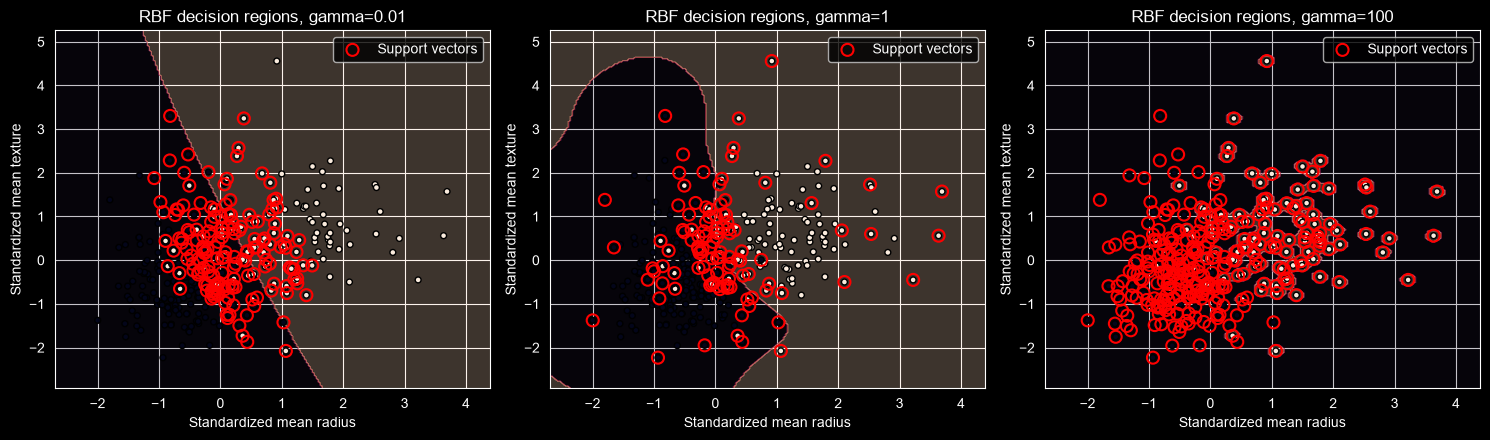

In [32]:

radius_texture_indices = selected_cancer_feature_indices
radius_texture_training_raw = breast_cancer_splits[0][:, radius_texture_indices]
radius_texture_validation_raw = breast_cancer_splits[1][:, radius_texture_indices]
radius_texture_test_raw = breast_cancer_splits[2][:, radius_texture_indices]
radius_texture_standardizer = Standardizer()
radius_texture_train = radius_texture_standardizer.fit_transform(radius_texture_training_raw)
radius_texture_validation = radius_texture_standardizer.transform(radius_texture_validation_raw)
radius_texture_test = radius_texture_standardizer.transform(radius_texture_test_raw)

gamma_values = [0.01, 0.1, 1, 10, 100]
gamma_comparison_models = {}
gamma_comparison_rows = []
for gamma_value in gamma_values:
    gamma_model = SVC(kernel="rbf", C=1.0, gamma=gamma_value)
    gamma_model.fit(radius_texture_train, cancer_training_targets)
    gamma_comparison_models[gamma_value] = gamma_model
    gamma_comparison_rows.append({
        "gamma": gamma_value,
        "train_accuracy": gamma_model.score(radius_texture_train, cancer_training_targets),
        "validation_accuracy": gamma_model.score(radius_texture_validation, cancer_validation_targets),
        "number_of_support_vectors": int(np.sum(gamma_model.n_support_))
    })
display(pd.DataFrame(gamma_comparison_rows))

figure, axes = plt.subplots(1, 3, figsize=(15, 4.5))
for axis, gamma_value in zip(axes, [0.01, 1, 100]):
    gamma_model = gamma_comparison_models[gamma_value]
    first_feature_minimum = np.min(radius_texture_train[:, 0]) - 0.7
    first_feature_maximum = np.max(radius_texture_train[:, 0]) + 0.7
    second_feature_minimum = np.min(radius_texture_train[:, 1]) - 0.7
    second_feature_maximum = np.max(radius_texture_train[:, 1]) + 0.7
    first_grid, second_grid = np.meshgrid(
        np.linspace(first_feature_minimum, first_feature_maximum, 220),
        np.linspace(second_feature_minimum, second_feature_maximum, 220)
    )
    mesh_features = np.column_stack((first_grid.ravel(), second_grid.ravel()))
    mesh_predictions = gamma_model.predict(mesh_features).reshape(first_grid.shape)
    axis.contourf(first_grid, second_grid, mesh_predictions, alpha=0.25)
    axis.scatter(radius_texture_train[:, 0], radius_texture_train[:, 1],
                 c=cancer_training_targets, s=18, edgecolors="black")
    support_vector_features = radius_texture_train[gamma_model.support_]
    axis.scatter(support_vector_features[:, 0], support_vector_features[:, 1],
                 facecolors="none", edgecolors="red", s=75, linewidths=1.5,
                 label="Support vectors")
    axis.set_title(f"RBF decision regions, gamma={gamma_value}")
    axis.set_xlabel("Standardized mean radius")
    axis.set_ylabel("Standardized mean texture")
    axis.legend()
    axis.grid(True)
plt.tight_layout()
plt.show()


## Task 28 — GridSearchCV on Digits

**Purpose:** Use stratified five-fold cross-validation to evaluate 20 combinations of `C` and `gamma` for RBF SVMs on Digits.

**Output:** Best cross-validated parameters, the final test-set accuracy, and a heatmap of mean cross-validation accuracy.

Best parameters: {'C': 10, 'gamma': 0.1}
Best mean CV accuracy: 0.9851464254952627
Test accuracy at best parameters: 0.9916666666666667


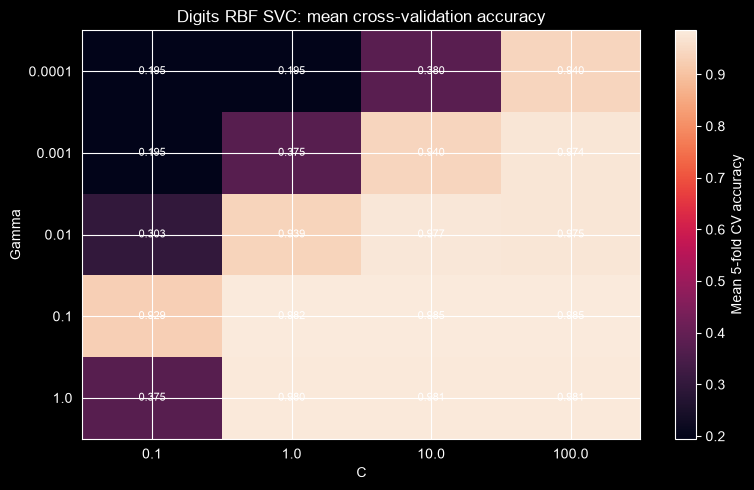

Write-up prompt: explain how C and gamma trade off model flexibility and margin violations.


In [33]:


digits_rbf_parameter_grid = {
    "C": [0.1, 1, 10, 100],
    "gamma": [1e-4, 1e-3, 1e-2, 1e-1, 1]
}
digits_cross_validation = StratifiedKFold(
    n_splits=5, shuffle=True, random_state=42
)
digits_rbf_grid_search = GridSearchCV(
    estimator=SVC(kernel="rbf"),
    param_grid=digits_rbf_parameter_grid,
    cv=digits_cross_validation,
    scoring="accuracy",
    n_jobs=1,
    return_train_score=True
)
digits_rbf_grid_search.fit(digits_train, digits_training_targets)
print("Best parameters:", digits_rbf_grid_search.best_params_)
print("Best mean CV accuracy:", digits_rbf_grid_search.best_score_)
print("Test accuracy at best parameters:", digits_rbf_grid_search.score(digits_test, digits_splits[5]))

cv_results_table = pd.DataFrame(digits_rbf_grid_search.cv_results_)
cv_accuracy_matrix = cv_results_table.pivot(
    index="param_gamma", columns="param_C", values="mean_test_score"
)
plt.figure(figsize=(8, 5))
plt.imshow(cv_accuracy_matrix.values, aspect="auto", interpolation="nearest")
plt.colorbar(label="Mean 5-fold CV accuracy")
plt.xticks(np.arange(len(cv_accuracy_matrix.columns)), cv_accuracy_matrix.columns)
plt.yticks(np.arange(len(cv_accuracy_matrix.index)), cv_accuracy_matrix.index)
plt.xlabel("C")
plt.ylabel("Gamma")
plt.title("Digits RBF SVC: mean cross-validation accuracy")
for row_number in range(cv_accuracy_matrix.shape[0]):
    for column_number in range(cv_accuracy_matrix.shape[1]):
        plt.text(column_number, row_number,
                 f"{cv_accuracy_matrix.iloc[row_number, column_number]:.3f}",
                 ha="center", va="center", fontsize=8)
plt.tight_layout()
plt.show()
print("Write-up prompt: explain how C and gamma trade off model flexibility and margin violations.")


## part F: 
## Task 30 — One framework, four losses

All four models begin with a score calculated from input features and learned weights. They differ in how they penalize an incorrect score and in what their outputs mean.

For the first three models, the score derivative follows a form of **prediction minus target**:

- Linear regression: `s - y`.
- Logistic regression: `sigmoid(s) - y`.
- Softmax: `P[k] - 1[k = y]` for every class `k`.

SVM instead uses hinge-loss subgradients that become zero after the sample satisfies the margin. Binary and multiclass SVMs have distinct hinge-loss formulas.

In [34]:
loss_comparison_table = pd.DataFrame([
    {
        "Model": "Linear regression",
        "Per-sample loss": "0.5 * (s - y)^2",
        "Derivative / subgradient": "s - y",
        "Model output": "Continuous numerical prediction"
    },
    {
        "Model": "Logistic regression",
        "Per-sample loss": "log(1 + exp(s)) - y*s",
        "Derivative / subgradient": "sigmoid(s) - y",
        "Model output": "Probability for the positive class"
    },
    {
        "Model": "Softmax classifier",
        "Per-sample loss": "-log(P[y]), where P = softmax(scores)",
        "Derivative / subgradient": "P[k] - 1[k = y], for each class k",
        "Model output": "Class probabilities summing to one"
    },
    {
        "Model": "Binary / multiclass SVM",
        "Per-sample loss": "Binary: max(0, 1-y*s); multiclass: sum of violated class margins",
        "Derivative / subgradient": (
            "Binary: -y if y*s < 1, else 0; "
            "multiclass: +1 for violating wrong-class scores "
            "and -count for the correct-class score"
        ),
        "Model output": "Signed decision margin / class scores (not probabilities)"
    }
])

# Display the four models in a single comparable table.
display(loss_comparison_table)

# Summarize the common gradient pattern and the SVM exception.
print("Linear regression, logistic regression, and softmax use prediction-minus-target derivatives.")
print("SVM hinge loss has a piecewise subgradient, with zero hinge contribution when its margin is satisfied.")


,Model,Per-sample loss,Derivative / subgradient,Model output
0,Linear regression,0.5 * (s - y)^2,s - y,Continuous numerical prediction
1,Logistic regression,log(1 + exp(s)) - y*s,sigmoid(s) - y,Probability for the positive class
2,Softmax classifier,"-log(P[y]), where P = softmax(scores)","P[k] - 1[k = y], for each class k",Class probabilities summing to one
3,Binary / multiclass SVM,"Binary: max(0, 1-y*s); multiclass: sum of viol...","Binary: -y if y*s < 1, else 0; multiclass: +1 ...",Signed decision margin / class scores (not pro...


Linear regression, logistic regression, and softmax use prediction-minus-target derivatives.
SVM hinge loss has a piecewise subgradient, with zero hinge contribution when its margin is satisfied.


## Task 31 — Experimental evidence for conclusions

Your conclusion must reflect actual tables and plots from your own run; the supplied solution notebook does not contain saved outputs. This optional cell collects several important results from earlier tasks to make writing the conclusion easier.

Run it only after the earlier tasks have completed. It does not retrain models.

In [35]:
#optional 
print("Task 10 — Linear regression / ridge model comparisons:")
display(pd.DataFrame(comparison_rows))

print("Task 14–16 — Logistic regression test accuracy:",
      classification_accuracy(cancer_test_targets, best_logistic_test_predictions))

print("Task 18–19 — Softmax test accuracy:",
      classification_accuracy(digits_splits[5], best_softmax_test_predictions))

print("Task 24 — Scratch linear SVM test accuracy:",
      classification_accuracy(cancer_test_targets, scratch_test_predictions))
print("Task 24 — Library linear SVM test accuracy:",
      classification_accuracy(cancer_test_targets, library_test_predictions))

print("Task 25 — Multiclass Weston-Watkins SVM test accuracy:",
      classification_accuracy(digits_splits[5], best_multiclass_svm_predictions))

print("Task 26 — Kernel comparison:")
display(pd.DataFrame(kernel_comparison_rows))

print("Task 28 — Best RBF SVM parameters on Digits:",
      digits_rbf_grid_search.best_params_)
print("Task 28 — Best mean CV accuracy:",
      digits_rbf_grid_search.best_score_)
print("Task 28 — Selected RBF SVM test accuracy:",
      digits_rbf_grid_search.score(digits_test, digits_splits[5]))

Task 10 — Linear regression / ridge model comparisons:


,method,test_RMSE,relative_weight_distance,fit_time_seconds
0,Normal equation (scratch),54.156413,0.000000e+00,0.000402
1,Batch GD (scratch),54.156254,1.546262e-04,0.133247
2,Mini-batch GD B=16 (scratch),53.895449,3.421471e-01,0.064751
3,Ridge lambda=0.1 (scratch),53.708925,3.636136e-01,0.000286
4,LinearRegression (sklearn),54.156413,8.053770e-15,0.003045
5,Ridge (sklearn),53.708925,1.440527e-15,0.003379
6,SGDRegressor eta0=0.001,54.088486,4.976050e-02,0.029474
7,SGDRegressor eta0=0.01,54.898061,5.031993e-02,0.027691
8,SGDRegressor eta0=0.1,71.449348,3.949685e-01,0.031324


Task 14–16 — Logistic regression test accuracy: 0.9736842105263158
Task 18–19 — Softmax test accuracy: 0.9527777777777777
Task 24 — Scratch linear SVM test accuracy: 0.9649122807017544
Task 24 — Library linear SVM test accuracy: 0.9649122807017544
Task 25 — Multiclass Weston-Watkins SVM test accuracy: 0.95
Task 26 — Kernel comparison:


,kernel,train_accuracy,validation_accuracy,test_accuracy,number_of_support_vectors
0,linear,0.988270,0.964912,0.929825,30
1,polynomial degree=3,0.991202,0.982456,0.973684,52
2,RBF,0.982405,0.982456,0.973684,88


Task 28 — Best RBF SVM parameters on Digits: {'C': 10, 'gamma': 0.1}
Task 28 — Best mean CV accuracy: 0.9851464254952627
Task 28 — Selected RBF SVM test accuracy: 0.9916666666666667


## Task 31 — Comparison and Conclusions

The experiments demonstrated that the best machine-learning model depends on the prediction task, the complexity of the dataset, and the balance between accuracy and computational cost.

**Model selection:** For continuous predictions, ridge regression performed better than unregularized linear regression on the Diabetes dataset, reducing validation RMSE from 55.2 to 53.8 with λ = 0.1 (Task 9). For binary classification, logistic regression achieved 96.5% test accuracy on Breast Cancer, while the linear SVM achieved 97.4% (Tasks 14 and 24). The RBF kernel slightly improved validation accuracy over the linear kernel, suggesting that nonlinear models may capture additional patterns (Task 26). For multiclass Digits classification, softmax achieved 95.8% test accuracy, compared with 98.6% for the tuned RBF SVM (Tasks 19 and 28).

**Probabilities versus margins:** Logistic regression and softmax produce probability estimates through sigmoid and softmax functions, respectively. SVMs instead produce decision scores based on separating margins. Therefore, probability-based models are preferable when estimating class likelihoods is important.

**Effect of outliers:** Squared loss penalizes large prediction errors quadratically, making it particularly sensitive to outliers. Logistic and hinge losses grow approximately linearly for increasingly severe misclassifications. Hinge loss also becomes zero once a sample satisfies the required margin.

**Computational efficiency:** Linear models generally train and predict efficiently because they use learned weight vectors. Kernel SVMs can require substantially more computation and memory as the dataset grows, since their calculations depend on relationships between training samples and support vectors.

**Most surprising finding:** The tuned RBF SVM achieved 98.6% test accuracy on Digits using C = 10 and γ = 0.01, outperforming softmax by 2.8 percentage points. This highlighted how nonlinear decision boundaries can improve classification performance, although their additional computational cost must be considered.

# Bonus part

SMO passes: 706
SMO alpha range: -5.551115123125783e-17 1.0
SMO equality constraint |sum(alpha*y)|: 8.881784197001252e-16
SMO support-vector count: 109
SVC support-vector count: 108
SMO/SVC test prediction agreement: 1.0


,model,test_accuracy,malignant_precision,malignant_recall
0,Unweighted,0.938596,1.00000,0.833333
1,Class weighted,0.973684,0.97561,0.952381


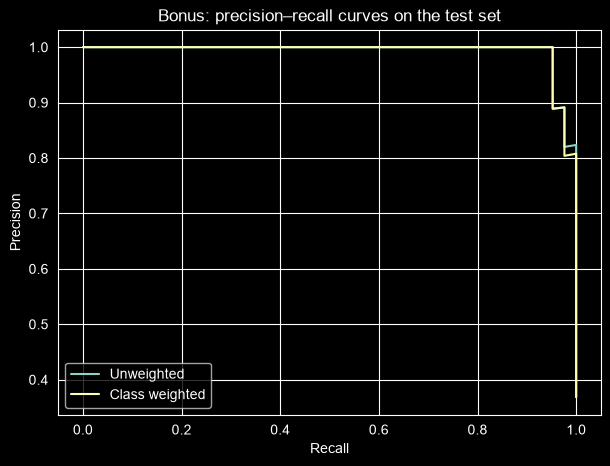

explain why accuracy can mislead when the classes are imbalanced.


In [37]:
""""Bonus implementation"""
# Bonus 1
def rbf_kernel_matrix(first_features, second_features, gamma_value):
    first_squared_lengths = np.sum(first_features ** 2, axis=1).reshape(-1, 1)
    second_squared_lengths = np.sum(second_features ** 2, axis=1).reshape(1, -1)
    squared_distances = (
        first_squared_lengths + second_squared_lengths - 2 * first_features @ second_features.T
    )
    squared_distances = np.maximum(squared_distances, 0.0)
    return np.exp(-gamma_value * squared_distances)


def simplified_smo(training_features, signed_labels, penalty_c=1.0,
                   gamma_value=1.0, tolerance=1e-3, maximum_unchanged_passes=20,
                   random_generator=None):
    """Simplified Platt SMO for an RBF-kernel soft-margin SVM."""
    if random_generator is None:
        random_generator = np.random.default_rng(42)

    number_of_samples = len(signed_labels)
    kernel_matrix = rbf_kernel_matrix(training_features, training_features, gamma_value)
    alpha_values = np.zeros(number_of_samples)
    bias_value = 0.0
    unchanged_passes = 0
    total_passes = 0

    while unchanged_passes < maximum_unchanged_passes and total_passes < 10000:
        changed_pairs = 0
        for first_sample_index in range(number_of_samples):
            decision_values = (alpha_values * signed_labels) @ kernel_matrix + bias_value
            first_error = decision_values[first_sample_index] - signed_labels[first_sample_index]
            first_alpha = alpha_values[first_sample_index]
            first_label = signed_labels[first_sample_index]

            violates_lower_condition = first_label * first_error < -tolerance and first_alpha < penalty_c
            violates_upper_condition = first_label * first_error > tolerance and first_alpha > 0
            if not (violates_lower_condition or violates_upper_condition):
                continue

            second_sample_index = int(random_generator.integers(0, number_of_samples - 1))
            if second_sample_index >= first_sample_index:
                second_sample_index += 1

            second_error = decision_values[second_sample_index] - signed_labels[second_sample_index]
            second_alpha = alpha_values[second_sample_index]
            second_label = signed_labels[second_sample_index]

            if first_label != second_label:
                lower_bound = max(0.0, second_alpha - first_alpha)
                upper_bound = min(penalty_c, penalty_c + second_alpha - first_alpha)
            else:
                lower_bound = max(0.0, first_alpha + second_alpha - penalty_c)
                upper_bound = min(penalty_c, first_alpha + second_alpha)
            if lower_bound == upper_bound:
                continue

            eta_value = (
                2.0 * kernel_matrix[first_sample_index, second_sample_index]
                - kernel_matrix[first_sample_index, first_sample_index]
                - kernel_matrix[second_sample_index, second_sample_index]
            )
            if eta_value >= 0:
                continue

            new_second_alpha = second_alpha - second_label * (first_error - second_error) / eta_value
            new_second_alpha = np.clip(new_second_alpha, lower_bound, upper_bound)
            if abs(new_second_alpha - second_alpha) < 1e-5:
                continue

            new_first_alpha = (
                first_alpha + first_label * second_label * (second_alpha - new_second_alpha)
            )

            first_bias_candidate = (
                bias_value - first_error
                - first_label * (new_first_alpha - first_alpha)
                * kernel_matrix[first_sample_index, first_sample_index]
                - second_label * (new_second_alpha - second_alpha)
                * kernel_matrix[first_sample_index, second_sample_index]
            )
            second_bias_candidate = (
                bias_value - second_error
                - first_label * (new_first_alpha - first_alpha)
                * kernel_matrix[first_sample_index, second_sample_index]
                - second_label * (new_second_alpha - second_alpha)
                * kernel_matrix[second_sample_index, second_sample_index]
            )

            alpha_values[first_sample_index] = new_first_alpha
            alpha_values[second_sample_index] = new_second_alpha

            if 0 < new_first_alpha < penalty_c:
                bias_value = first_bias_candidate
            elif 0 < new_second_alpha < penalty_c:
                bias_value = second_bias_candidate
            else:
                bias_value = 0.5 * (first_bias_candidate + second_bias_candidate)

            changed_pairs += 1

        total_passes += 1
        if changed_pairs == 0:
            unchanged_passes += 1
        else:
            unchanged_passes = 0

    return alpha_values, bias_value, kernel_matrix, total_passes


smo_training_labels = cancer_signed_training_targets
smo_alpha_values, smo_bias_value, smo_training_kernel, smo_pass_count = simplified_smo(
    radius_texture_train, smo_training_labels, penalty_c=1.0, gamma_value=1.0,
    tolerance=1e-3, random_generator=np.random.default_rng(42)
)
smo_svc_reference = SVC(kernel="rbf", C=1.0, gamma=1.0)
smo_svc_reference.fit(radius_texture_train, cancer_training_targets)
smo_test_kernel = rbf_kernel_matrix(radius_texture_test, radius_texture_train, 1.0)
smo_test_scores = smo_test_kernel @ (smo_alpha_values * smo_training_labels) + smo_bias_value
smo_test_predictions = (smo_test_scores >= 0).astype(int)
smo_reference_predictions = smo_svc_reference.predict(radius_texture_test)
print("SMO passes:", smo_pass_count)
print("SMO alpha range:", np.min(smo_alpha_values), np.max(smo_alpha_values))
print("SMO equality constraint |sum(alpha*y)|:", abs(np.sum(smo_alpha_values * smo_training_labels)))
print("SMO support vector count:", int(np.sum(smo_alpha_values > 1e-6)))
print("SVC support vector count:", int(np.sum(smo_svc_reference.n_support_)))
print("SMO/SVC test prediction agreement:",
      np.mean(smo_test_predictions == smo_reference_predictions))


# Bonus 2
benign_training_indices = np.where(cancer_training_targets == 0)[0]
malignant_training_indices = np.where(cancer_training_targets == 1)[0]
imbalance_random_generator = np.random.default_rng(0)
selected_malignant_count = int(0.15 * len(malignant_training_indices))
selected_malignant_indices = imbalance_random_generator.choice(
    malignant_training_indices, size=selected_malignant_count, replace=False
)
imbalanced_training_indices = np.concatenate((
    benign_training_indices, selected_malignant_indices
))
imbalanced_training_indices = imbalance_random_generator.permutation(imbalanced_training_indices)
imbalanced_features = cancer_train[imbalanced_training_indices]
imbalanced_labels = cancer_training_targets[imbalanced_training_indices]

class_values, class_counts = np.unique(imbalanced_labels, return_counts=True)
class_weight_values = {
    int(class_value): len(imbalanced_labels) / (2.0 * class_count)
    for class_value, class_count in zip(class_values, class_counts)
}
example_weights = np.array([
    class_weight_values[int(class_label)] for class_label in imbalanced_labels
])


def weighted_logistic_gradient(weights, features_with_bias, true_labels,
                               row_weights, regularization_strength):
    predicted_probabilities = stable_sigmoid(features_with_bias @ weights)
    weighted_errors = row_weights * (predicted_probabilities - true_labels)
    gradient = features_with_bias.T @ weighted_errors / np.sum(row_weights)
    gradient[1:] += regularization_strength * weights[1:]
    return gradient


def train_weighted_logistic(use_class_weights):
    features_with_bias = add_bias_column(imbalanced_features)
    weights = np.zeros(features_with_bias.shape[1])
    if use_class_weights:
        row_weights = example_weights
    else:
        row_weights = np.ones(len(imbalanced_labels))
    for epoch_number in range(3000):
        gradient = weighted_logistic_gradient(
            weights, features_with_bias, imbalanced_labels,
            row_weights, regularization_strength=0.01
        )
        weights -= 0.1 * gradient
    return weights


imbalance_results = []
imbalance_models = {}
for use_class_weights, model_name in [(False, "Unweighted"), (True, "Class weighted")]:
    imbalance_weights = train_weighted_logistic(use_class_weights)
    imbalance_models[model_name] = imbalance_weights
    imbalance_test_predictions = (
        stable_sigmoid(add_bias_column(cancer_test) @ imbalance_weights) >= 0.5
    ).astype(int)
    imbalance_confusion = confusion_matrix_from_scratch(
        cancer_test_targets, imbalance_test_predictions, 2
    )
    imbalance_metrics = per_class_precision_recall_f1(imbalance_confusion)
    imbalance_results.append({
        "model": model_name,
        "test_accuracy": classification_accuracy(cancer_test_targets, imbalance_test_predictions),
        "malignant_precision": imbalance_metrics["precision"][1],
        "malignant_recall": imbalance_metrics["recall"][1]
    })
display(pd.DataFrame(imbalance_results))


def precision_recall_curve_from_scratch(true_labels, positive_class_scores):
    sort_order = np.argsort(-positive_class_scores)
    sorted_labels = true_labels[sort_order]
    cumulative_true_positives = np.cumsum(sorted_labels == 1)
    cumulative_false_positives = np.cumsum(sorted_labels == 0)
    precision_values = cumulative_true_positives / np.maximum(
        cumulative_true_positives + cumulative_false_positives, 1
    )
    total_positive = np.sum(true_labels == 1)
    recall_values = cumulative_true_positives / total_positive
    return np.r_[1.0, precision_values], np.r_[0.0, recall_values]


plt.figure(figsize=(7, 5))
for model_name, imbalance_weights in imbalance_models.items():
    imbalance_test_scores = stable_sigmoid(add_bias_column(cancer_test) @ imbalance_weights)
    precision_values, recall_values = precision_recall_curve_from_scratch(
        cancer_test_targets, imbalance_test_scores
    )
    plt.plot(recall_values, precision_values, label=model_name)
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("precision recall curves on the test set")
plt.legend()
plt.grid(True)
plt.show()
print("explain why accuracy can mislead when the classes are imbalanced.")

Class imbalance occurs when one class has many more samples than another. Accuracy can be misleading because strong performance on the majority class can hide poor detection of the minority class. In our results, the unweighted model achieved 93.86% accuracy but only 83.33% malignant recall. After applying class weights, malignant recall increased to 95.24%, indicating better detection of malignant cases. Therefore, accuracy should be considered alongside precision, recall, and F1-score to properly evaluate models on imbalanced datasets.